# Comprensión de los datos y EDA — Modelo de riesgo crediticio
## PIM5 · Avance 1 (V1.0.1) · `comprension_eda.ipynb`

---

## Índice

1. [Introducción y objetivo](#1)
2. [Importación de librerías](#2)
3. [Carga y exploración inicial de datos](#3)
4. [Tipos de variables](#4)
5. [Calidad de datos](#5)
6. [Variable objetivo y desbalanceo de clases](#6)
7. [Análisis exploratorio (univariable, bivariable y multivariable)](#7)
8. [Detección de outliers (IQR)](#8)
9. [Posible fuga de información en `puntaje`](#9)
10. [Análisis temporal de `fecha_prestamo`](#10)
11. [Hallazgos y decisiones para el Avance 2](#11)

---

<a id="1"></a>
## 1. Introducción y objetivo

Una empresa financiera necesita **anticipar el comportamiento de pago de nuevos solicitantes de crédito** a partir de información histórica de créditos. La variable a predecir es `Pago_atiempo`: **1** si el crédito se pagó a tiempo y **0** si no.

El objetivo de este notebook es **comprender los datos antes de modelar**: revisar su calidad, describir cada variable (análisis univariable), estudiar su relación con el comportamiento de pago (bivariable) y las relaciones entre variables (multivariable), y dejar registradas las decisiones que se aplicarán en la ingeniería de características del Avance 2.

**Alcance de este avance:** exploración y diagnóstico. No se imputan valores, no se codifican variables ni se divide en entrenamiento/prueba: esas transformaciones se implementarán en `ft_engineering.py` (Avance 2), ajustadas únicamente con datos de entrenamiento para evitar fuga de información (*data leakage*).

**Aclaración sobre los datos:** la base es **sintética** y de calidad limitada. Algunas relaciones pueden resultar poco realistas; se documentan tal como se observan, sin forzar interpretaciones.

**Convenciones de lectura**
- Verde/azul = crédito pagado a tiempo (1). Rojo = no pagado a tiempo (0).
- Cuando se habla de "tasa de no pago" se refiere al porcentaje de créditos con `Pago_atiempo = 0`.

<a id="2"></a>
## 2. Importación de librerías

In [1]:
# ===== MANIPULACIÓN DE DATOS =====
import pandas as pd
import numpy as np
from pathlib import Path

# ===== VISUALIZACIÓN =====
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# ===== ESTADÍSTICA Y MÉTRICAS =====
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import roc_auc_score

# ===== UTILIDADES =====
import warnings
warnings.filterwarnings('ignore')

# --- Reproducibilidad ---
# Se fija la semilla para que las muestras aleatorias (p. ej. el pairplot) sean siempre las mismas.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Configuración general de gráficos y tablas ---
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Colores consistentes en todo el notebook
COLOR_PAGO = '#2E86AB'      # 1 = pagó a tiempo
COLOR_NO_PAGO = '#E63946'   # 0 = no pagó a tiempo
PALETA = {0: COLOR_NO_PAGO, 1: COLOR_PAGO}

print('Librerías importadas correctamente.')
print(f'Pandas versión: {pd.__version__}')

Librerías importadas correctamente.
Pandas versión: 3.0.6


<a id="3"></a>
## 3. Carga y exploración inicial de datos

In [2]:
# Ruta al CSV: este notebook vive en mlops_pipeline/src/, la raíz del repositorio está dos niveles arriba.
RUTA_DATOS = Path('../Base_de_datos.csv')


def cargar_datos(ruta=RUTA_DATOS):
    '''Carga la base histórica de créditos (misma función que en Cargar_datos.ipynb).'''
    return pd.read_csv(ruta, parse_dates=['fecha_prestamo'])


df = cargar_datos()

print('INFORMACIÓN GENERAL DEL DATASET')
print('=' * 70)
print(f'Número de créditos (filas):     {df.shape[0]:,}')
print(f'Número de variables (columnas): {df.shape[1]}')
print(f'Período de fecha_prestamo:      {df["fecha_prestamo"].min():%d/%m/%Y} a {df["fecha_prestamo"].max():%d/%m/%Y}')
print()
df.head()

INFORMACIÓN GENERAL DEL DATASET
Número de créditos (filas):     10,763
Número de variables (columnas): 23
Período de fecha_prestamo:      26/11/2024 a 26/04/2026



,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,7,2024-12-21 11:31:35,"3,692,160.00",10,42,Independiente,8000000,2500000,341296,88.77,695.00,10,5,0.00,"51,258.00","51,258.00",0.00,5,0,0,"908,526.00",Estable,1
1,4,2025-04-22 09:47:35,"840,000.00",6,60,Empleado,3000000,2000000,124876,95.23,789.00,3,1,0.00,"8,673.00","8,673.00",0.00,0,0,2,"939,017.00",Creciente,1
2,9,2026-01-08 12:22:40,"5,974,028.40",10,36,Independiente,4036000,829000,529554,47.61,740.00,4,5,0.00,"18,702.00","18,702.00",0.00,3,0,0,NaN,NaN,0
3,4,2025-08-04 12:04:10,"1,671,240.00",6,48,Empleado,1524547,498000,252420,95.23,837.00,4,4,0.00,"15,782.00","15,782.00",0.00,3,0,0,"1,536,193.00",Creciente,1
4,9,2025-04-26 11:24:26,"2,781,636.00",11,44,Empleado,5000000,4000000,217037,95.23,771.00,4,6,0.00,"204,804.00","204,804.00",0.00,3,0,1,"933,473.00",Creciente,1


In [3]:
# Tipos de datos e información general
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  int64         
 1   fecha_prestamo                 10763 non-null  datetime64[us]
 2   capital_prestado               10763 non-null  float64       
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10763 non-null  int64         
 5   tipo_laboral                   10763 non-null  str           
 6   salario_cliente                10763 non-null  int64         
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje                        10763 non-null  float64       
 10  puntaje_datacredito            10757 non-null  float64       
 11  cant_creditosvigentes     

In [4]:
# Estadísticas descriptivas
# Se separan las numéricas de las de texto para no mezclar los indicadores de cada tipo.
print('Variables numéricas:')
display(df.select_dtypes('number').describe().T)

print('\nVariables de texto / categóricas:')
display(df.select_dtypes(exclude=['number', 'datetime']).describe().T)

Variables numéricas:


,count,mean,std,min,25%,50%,75%,max
tipo_credito,"10,763.00",5.41,2.34,4.00,4.00,4.00,9.00,68.00
capital_prestado,"10,763.00","2,434,315.00","1,909,642.76","360,000.00","1,224,831.00","1,921,920.00","3,084,840.00","41,444,152.80"
plazo_meses,"10,763.00",10.58,6.63,2.00,6.00,10.00,12.00,90.00
edad_cliente,"10,763.00",43.95,15.06,19.00,33.00,42.00,53.00,123.00
salario_cliente,"10,763.00","17,216,431.46","355,476,717.60",0.00,"2,000,000.00","3,000,000.00","4,875,808.00","22,000,000,000.00"
total_otros_prestamos,"10,763.00","6,238,869.65","118,418,316.94",0.00,"500,000.00","1,000,000.00","2,000,000.00","6,787,675,263.00"
cuota_pactada,"10,763.00","243,617.41","210,493.69","23,944.00","121,041.50","182,863.00","287,833.50","3,816,752.00"
puntaje,"10,763.00",91.17,16.47,-38.01,95.23,95.23,95.23,95.23
puntaje_datacredito,"10,757.00",780.79,104.88,-7.00,757.00,791.00,825.00,999.00
cant_creditosvigentes,"10,763.00",5.73,3.98,0.00,3.00,5.00,8.00,62.00



Variables de texto / categóricas:


,count,unique,top,freq
tipo_laboral,10763,2,Empleado,6754
tendencia_ingresos,7831,46,Creciente,5294


**Lectura inicial.** La base tiene 10.763 créditos y 23 variables, sin filas duplicadas. Tres observaciones guían el resto del análisis:

1. Hay **valores extremos**: `edad_cliente` llega a 123 años, `salario_cliente` a 22.000 millones y `total_otros_prestamos` a 6.788 millones (secciones 5 y 8).
2. `puntaje` tiene los percentiles 25, 50 y 75 en el mismo valor (95,23): casi toda la variable toma un único valor (sección 9).
3. Siete columnas tienen nulos; dos de ellas rondan el 27 % (sección 5).

<a id="4"></a>
## 4. Tipos de variables

La base **no incluye un diccionario de variables**, por lo que la clasificación siguiente se infiere del nombre de cada columna y de sus valores reales. Las columnas cuyo significado exacto no está documentado se señalan para confirmarlas con el equipo.

In [5]:
# --- Clasificación de las variables ---
variable_objetivo = 'Pago_atiempo'      # 1 = pagó a tiempo, 0 = no pagó a tiempo
variable_fecha = 'fecha_prestamo'

# Categóricas nominales (sin orden natural). tipo_credito viene como número pero es un código de producto.
categoricas = ['tipo_credito', 'tipo_laboral', 'tendencia_ingresos']

# Numéricas discretas: conteos o valores enteros acotados
discretas = ['plazo_meses', 'edad_cliente', 'cant_creditosvigentes', 'huella_consulta',
             'creditos_sectorFinanciero', 'creditos_sectorCooperativo', 'creditos_sectorReal']

# Numéricas continuas: montos, saldos y puntajes
continuas = ['capital_prestado', 'salario_cliente', 'total_otros_prestamos', 'cuota_pactada',
             'puntaje', 'puntaje_datacredito', 'saldo_mora', 'saldo_total', 'saldo_principal',
             'saldo_mora_codeudor', 'promedio_ingresos_datacredito']

variables_numericas = continuas + discretas

# Control: todas las columnas deben quedar clasificadas exactamente una vez
clasificadas = [variable_objetivo, variable_fecha] + categoricas + discretas + continuas
assert sorted(clasificadas) == sorted(df.columns), 'Hay columnas sin clasificar o repetidas'

# Tabla resumen de la clasificación
tipo_por_variable = {variable_objetivo: 'Objetivo (binaria)', variable_fecha: 'Fecha'}
tipo_por_variable.update({c: 'Categórica nominal' for c in categoricas})
tipo_por_variable.update({c: 'Numérica discreta' for c in discretas})
tipo_por_variable.update({c: 'Numérica continua' for c in continuas})

tipos = pd.DataFrame({
    'variable': df.columns,
    'tipo': [tipo_por_variable[c] for c in df.columns],
    'dtype_leido': df.dtypes.astype(str).values,
    'valores_distintos': df.nunique().values,
})
tipos.sort_values(['tipo', 'variable']).reset_index(drop=True)

,variable,tipo,dtype_leido,valores_distintos
0,tendencia_ingresos,Categórica nominal,str,46
1,tipo_credito,Categórica nominal,int64,6
2,tipo_laboral,Categórica nominal,str,2
3,fecha_prestamo,Fecha,datetime64[us],10758
4,capital_prestado,Numérica continua,float64,7306
5,cuota_pactada,Numérica continua,int64,9836
6,promedio_ingresos_datacredito,Numérica continua,float64,5309
7,puntaje,Numérica continua,float64,248
8,puntaje_datacredito,Numérica continua,float64,315
9,salario_cliente,Numérica continua,int64,1385


**Observaciones sobre la clasificación**

- `tipo_credito` se lee como número entero, pero es un **código de producto** (6 valores distintos, sin orden): se trata como categórica nominal.
- `fecha_prestamo` se conserva como fecha y se analiza en la sección 10.
- Quedan **por confirmar con el equipo** el significado exacto de `puntaje` y `puntaje_datacredito`, de los saldos (`saldo_mora`, `saldo_total`, `saldo_principal`, `saldo_mora_codeudor`) y de `huella_consulta`, porque la base no trae diccionario. Las interpretaciones de este notebook se limitan a lo que muestran los datos.

<a id="5"></a>
## 5. Calidad de datos

Antes de cualquier análisis se revisa: valores faltantes, duplicados, valores inválidos en variables categóricas y valores lógicamente imposibles o sospechosos. Se trabaja sobre una **copia** (`data`) para conservar intacto el dataset original (`df`).

### 5.1 Valores nulos y duplicados

VALORES NULOS POR COLUMNA


,n_nulos,pct_nulos
tendencia_ingresos,2932,27.24
promedio_ingresos_datacredito,2930,27.22
saldo_mora_codeudor,590,5.48
saldo_principal,405,3.76
saldo_mora,156,1.45
saldo_total,156,1.45
puntaje_datacredito,6,0.06



REGISTROS DUPLICADOS
Filas completamente duplicadas: 0


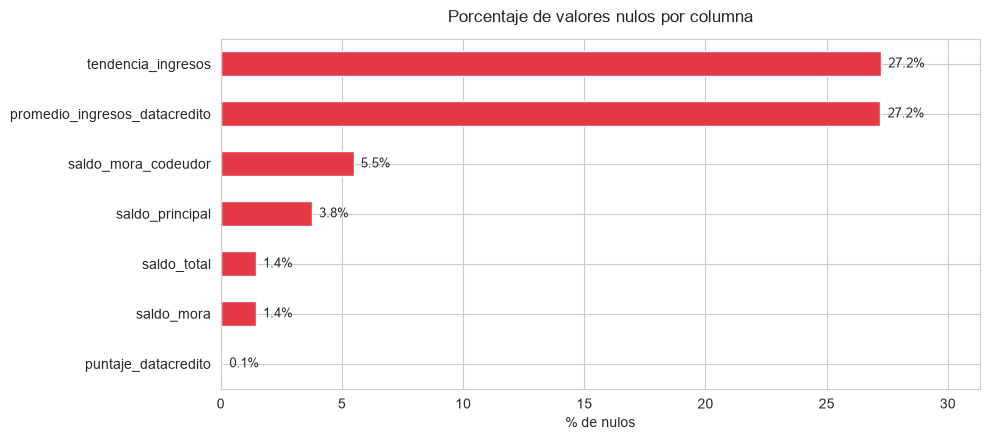

In [6]:
# --- Valores nulos ---
nulos = df.isnull().sum()
reporte_nulos = pd.DataFrame({'n_nulos': nulos, 'pct_nulos': (nulos / len(df) * 100).round(2)})
reporte_nulos = reporte_nulos[reporte_nulos['n_nulos'] > 0].sort_values('n_nulos', ascending=False)

print('VALORES NULOS POR COLUMNA')
print('=' * 70)
display(reporte_nulos)

# --- Duplicados ---
print('\nREGISTROS DUPLICADOS')
print('=' * 70)
print(f'Filas completamente duplicadas: {df.duplicated().sum()}')

# --- Visualización de los nulos ---
fig, ax = plt.subplots(figsize=(10, 4.5))
reporte_nulos['pct_nulos'].sort_values().plot(kind='barh', color=COLOR_NO_PAGO, ax=ax)
ax.set_title('Porcentaje de valores nulos por columna', pad=12)
ax.set_xlabel('% de nulos')
ax.set_xlim(0, reporte_nulos['pct_nulos'].max() * 1.15)
for i, v in enumerate(reporte_nulos['pct_nulos'].sort_values()):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

In [7]:
# ¿Los nulos de las dos variables con más faltantes coinciden en las mismas filas?
mismo_registro = (df['promedio_ingresos_datacredito'].isnull() & df['tendencia_ingresos'].isnull()).sum()
print(f'Filas con nulo en AMBAS (promedio_ingresos_datacredito y tendencia_ingresos): {mismo_registro:,}')

# ¿Tener el dato faltante se asocia con el comportamiento de pago?
sin_ingreso = df['promedio_ingresos_datacredito'].isnull()
comparacion = df.groupby(sin_ingreso)['Pago_atiempo'].agg(creditos='size', pct_pago_a_tiempo=lambda s: s.mean() * 100)
comparacion.index = ['Con dato de ingresos', 'Sin dato de ingresos']
comparacion

Filas con nulo en AMBAS (promedio_ingresos_datacredito y tendencia_ingresos): 2,930


,creditos,pct_pago_a_tiempo
Con dato de ingresos,7833,95.62
Sin dato de ingresos,2930,94.27


### 5.2 Valores inválidos y registros sospechosos

Se crea la copia de trabajo y se revisan tres problemas: valores numéricos dentro de una variable categórica (`tendencia_ingresos`), edades imposibles (`edad_cliente`) y otras inconsistencias lógicas.

In [8]:
# Copia de trabajo para no modificar el dataset original (df)
data = df.copy()

# --- tendencia_ingresos: solo son válidas tres categorías ---
categorias_validas = ['Creciente', 'Decreciente', 'Estable']
invalidos = data['tendencia_ingresos'].notna() & ~data['tendencia_ingresos'].isin(categorias_validas)

print('TENDENCIA_INGRESOS')
print('=' * 70)
print(f'Valores fuera de las 3 categorías esperadas: {invalidos.sum()}')
print('Ejemplos:', data.loc[invalidos, 'tendencia_ingresos'].unique()[:8].tolist())

# Los valores numéricos no corresponden a una variable categórica: se reemplazan por nulo.
data.loc[invalidos, 'tendencia_ingresos'] = np.nan
print('\nDistribución luego de la corrección:')
print(data['tendencia_ingresos'].value_counts(dropna=False).to_string())

TENDENCIA_INGRESOS
Valores fuera de las 3 categorías esperadas: 58
Ejemplos: ['8315', '0', '158042', '3978', '9147', '168750', '-28589', '1000000']

Distribución luego de la corrección:
tendencia_ingresos
Creciente      5294
NaN            2990
Decreciente    1291
Estable        1188


In [9]:
# --- edad_cliente: ¿hay edades imposibles? ---
print('EDAD_CLIENTE')
print('=' * 70)
print('Valores de edad por encima de 69 (máximo de la franja continua):')
print(data.loc[data['edad_cliente'] > 69, 'edad_cliente'].value_counts().sort_index().to_string())

EDAD_MAXIMA_PLAUSIBLE = 90   # umbral conservador para una persona solicitante de crédito
edad_invalida = data['edad_cliente'] > EDAD_MAXIMA_PLAUSIBLE
print(f'\nRegistros con edad > {EDAD_MAXIMA_PLAUSIBLE}: {edad_invalida.sum()} ({edad_invalida.mean() * 100:.2f}%)')
data.loc[edad_invalida, 'edad_cliente'] = np.nan   # se marcan como nulos para tratarlos en el Avance 2

EDAD_CLIENTE
Valores de edad por encima de 69 (máximo de la franja continua):
edad_cliente
121      4
122    144
123      2

Registros con edad > 90: 150 (1.39%)


In [10]:
# --- Otras inconsistencias lógicas y valores sospechosos (sobre el dataset original) ---
suma_sectores = df['creditos_sectorFinanciero'] + df['creditos_sectorCooperativo'] + df['creditos_sectorReal']

chequeos = pd.DataFrame([
    ('edad_cliente > 90', (df['edad_cliente'] > 90).sum(), 'Se marcan como nulos (valor imposible)'),
    ('tendencia_ingresos con valores numéricos', invalidos.sum(), 'Se marcan como nulos (ya aplicado)'),
    ('salario_cliente = 0', (df['salario_cliente'] == 0).sum(), 'Se conservan; revisar en el Avance 2'),
    ('cuota_pactada > salario_cliente', (df['cuota_pactada'] > df['salario_cliente']).sum(), 'Se conservan; posible señal de riesgo'),
    ('puntaje < 0', (df['puntaje'] < 0).sum(), 'Se conservan; ver sección 9'),
    ('puntaje_datacredito = 0', (df['puntaje_datacredito'] == 0).sum(), 'Probable código de "sin dato": se trata como nulo en el Avance 2'),
    ('puntaje_datacredito < 0', (df['puntaje_datacredito'] < 0).sum(), 'Se marca como inválido en el Avance 2'),
    ('tipo_credito con menos de 5 registros', df['tipo_credito'].isin(df['tipo_credito'].value_counts()[lambda s: s < 5].index).sum(), 'Se agrupan en "Otros" en el Avance 2'),
    ('cant_creditosvigentes distinto de la suma por sector', (df['cant_creditosvigentes'] != suma_sectores).sum(), 'Se conservan; relación no documentada'),
    ('saldo_total < saldo_principal', (df['saldo_total'] < df['saldo_principal']).sum(), 'Sin hallazgos'),
], columns=['chequeo', 'registros', 'decision'])
chequeos['pct_del_total'] = (chequeos['registros'] / len(df) * 100).round(2)
chequeos[['chequeo', 'registros', 'pct_del_total', 'decision']]

,chequeo,registros,pct_del_total,decision
0,edad_cliente > 90,150,1.39,Se marcan como nulos (valor imposible)
1,tendencia_ingresos con valores numéricos,58,0.54,Se marcan como nulos (ya aplicado)
2,salario_cliente = 0,24,0.22,Se conservan; revisar en el Avance 2
3,cuota_pactada > salario_cliente,35,0.33,Se conservan; posible señal de riesgo
4,puntaje < 0,135,1.25,Se conservan; ver sección 9
5,puntaje_datacredito = 0,145,1.35,"Probable código de ""sin dato"": se trata como n..."
6,puntaje_datacredito < 0,1,0.01,Se marca como inválido en el Avance 2
7,tipo_credito con menos de 5 registros,3,0.03,"Se agrupan en ""Otros"" en el Avance 2"
8,cant_creditosvigentes distinto de la suma por ...,7646,71.04,Se conservan; relación no documentada
9,saldo_total < saldo_principal,0,0.00,Sin hallazgos


**Hallazgos de calidad de datos**

- **Nulos.** Siete columnas tienen faltantes. `tendencia_ingresos` (27,24 %) y `promedio_ingresos_datacredito` (27,22 %) concentran la mayoría y **faltan en las mismas 2.930 filas**, por lo que no son faltantes independientes: sugiere un origen común (por ejemplo, clientes sin ingresos reportados), aunque la base no lo documenta. Los créditos sin dato de ingresos se pagaron a tiempo en 94,3 % de los casos frente a 95,6 % de los que sí lo tienen: la diferencia es pequeña, pero la **ausencia del dato podría aportar información por sí misma**. Las demás columnas tienen entre 0,06 % y 5,48 % de nulos.
- **Duplicados.** No hay filas duplicadas.
- **`tendencia_ingresos`.** Tiene 58 valores numéricos (0,54 %) dentro de una variable categórica de tres categorías; se reemplazaron por nulo. Sumados a los nulos originales, quedan 2.990 créditos sin dato (27,78 %).
- **`edad_cliente`.** Las edades llegan de forma continua hasta los 69 años y luego solo aparecen los valores 121, 122 y 123: **150 registros (1,39 %)**, 144 de ellos con 122. No es un patrón de edades reales sino de un valor centinela o un error de carga; se marcaron como nulos. Con esto, la edad queda entre 19 y 69 años (mediana 42).
- **`puntaje_datacredito`.** 145 registros (1,35 %) valen exactamente 0 y uno es negativo (−7). Un puntaje crediticio de 0 no parece un valor real: se interpreta como un código de "sin dato" y se tratará como nulo en el Avance 2.
- **Otras inconsistencias.** Hay 24 salarios en 0 y 35 créditos con cuota mayor al salario (0,33 %); se conservan. `tipo_credito` tiene los códigos 7 y 68 con solo 2 y 1 registros. `cant_creditosvigentes` **no coincide** con la suma de créditos por sector en el 71,04 % de los registros: la relación entre ambas no está documentada, lo que resta confiabilidad a esas variables.

<a id="6"></a>
## 6. Variable objetivo y desbalanceo de clases

`Pago_atiempo` indica si el crédito se pagó a tiempo (1) o no (0). El comportamiento que interesa anticipar es el **no pago** (clase 0), que es la clase minoritaria.

DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
No pagó a tiempo (0): 511 créditos (4.75%)
Pagó a tiempo (1):    10,252 créditos (95.25%)

Ratio de desbalanceo: 20.1 : 1
Exactitud (accuracy) de la predicción trivial "todos pagan": 95.25%


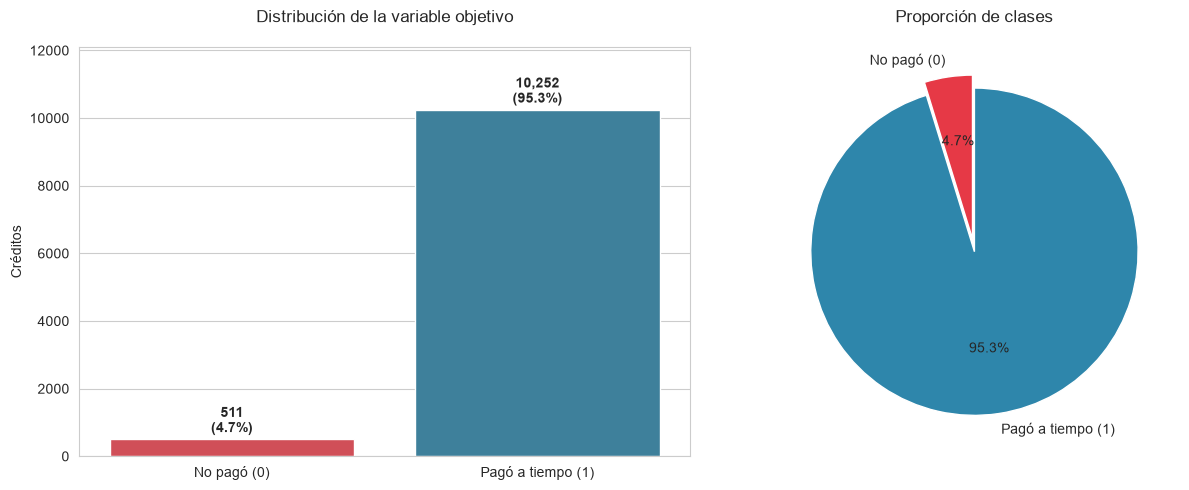

In [11]:
# Distribución de la variable objetivo
conteo = data['Pago_atiempo'].value_counts().sort_index()
porcentaje = data['Pago_atiempo'].value_counts(normalize=True).sort_index() * 100

print('DISTRIBUCIÓN DE LA VARIABLE OBJETIVO')
print('=' * 70)
print(f'No pagó a tiempo (0): {conteo[0]:,} créditos ({porcentaje[0]:.2f}%)')
print(f'Pagó a tiempo (1):    {conteo[1]:,} créditos ({porcentaje[1]:.2f}%)')
print(f'\nRatio de desbalanceo: {conteo[1] / conteo[0]:.1f} : 1')

# Un "modelo" que siempre prediga "pagará a tiempo" acertaría este porcentaje sin aprender nada:
print(f'Exactitud (accuracy) de la predicción trivial "todos pagan": {porcentaje[1]:.2f}%')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=data, x='Pago_atiempo', hue='Pago_atiempo', palette=PALETA, legend=False, ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['No pagó (0)', 'Pagó a tiempo (1)'])
axes[0].set_xlabel('')
axes[0].set_ylabel('Créditos')
axes[0].set_title('Distribución de la variable objetivo', pad=18)
axes[0].set_ylim(0, conteo.max() * 1.18)
for i, v in enumerate(conteo):
    axes[0].text(i, v + conteo.max() * 0.02, f'{v:,}\n({porcentaje[i]:.1f}%)', ha='center', fontweight='bold')

axes[1].pie(conteo, labels=['No pagó (0)', 'Pagó a tiempo (1)'], autopct='%1.1f%%',
            colors=[COLOR_NO_PAGO, COLOR_PAGO], startangle=90, explode=(0.08, 0))
axes[1].set_title('Proporción de clases', pad=18)

plt.tight_layout()
plt.show()

**Interpretación.** El desbalanceo es de **20,1 a 1**: solo 511 de 10.763 créditos (4,75 %) no se pagaron a tiempo. Consecuencias para el modelado del Avance 2:

- La exactitud (*accuracy*) **no sirve como métrica principal**: predecir que todos pagan ya da 95,25 %. Se usarán ROC-AUC, curva Precision-Recall, Precision, Recall y F1 de la clase "no pagó".
- Las particiones deben ser **estratificadas** para mantener la proporción de no pagos. Con un 20 % de prueba quedarían unos 102 no pagos: pocos casos, por lo que las métricas serán inestables y conviene complementarlas con validación cruzada.
- Se evaluarán estrategias para el desbalanceo (ponderación de clases y ajuste del umbral de decisión).

<a id="7"></a>
## 7. Análisis exploratorio de datos (EDA)

### 7.1 Análisis univariable

Se describe cada variable por separado. En las numéricas, las distribuciones muy asimétricas se grafican **recortadas en el percentil 99** (el título indica cuántos valores quedan fuera) para poder ver el cuerpo de la distribución; los extremos se analizan en la sección 8.

**Variables numéricas**

In [12]:
# Resumen estadístico ampliado: media vs. mediana y asimetría (skew) permiten detectar colas largas.
# skew > 1 indica una cola derecha marcada.
resumen_num = data[variables_numericas].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T
resumen_num

,count,mean,median,std,min,max,skew
capital_prestado,"10,763.00","2,434,315.00","1,921,920.00","1,909,642.76","360,000.00","41,444,152.80",3.72
salario_cliente,"10,763.00","17,216,431.46","3,000,000.00","355,476,717.60",0.00,"22,000,000,000.00",43.78
total_otros_prestamos,"10,763.00","6,238,869.65","1,000,000.00","118,418,316.94",0.00,"6,787,675,263.00",38.46
cuota_pactada,"10,763.00","243,617.41","182,863.00","210,493.69","23,944.00","3,816,752.00",3.79
puntaje,"10,763.00",91.17,95.23,16.47,-38.01,95.23,-4.87
puntaje_datacredito,"10,757.00",780.79,791.00,104.88,-7.00,999.00,-5.64
saldo_mora,"10,607.00",7.75,0.00,225.96,0.00,"12,534.00",40.57
saldo_total,"10,607.00","45,937.41","16,178.00","106,269.79",0.00,"5,116,066.00",20.20
saldo_principal,"10,358.00","40,346.17","14,442.50","71,242.44",0.00,"1,562,285.00",5.05
saldo_mora_codeudor,"10,173.00",0.26,0.00,21.77,0.00,"2,145.00",94.97


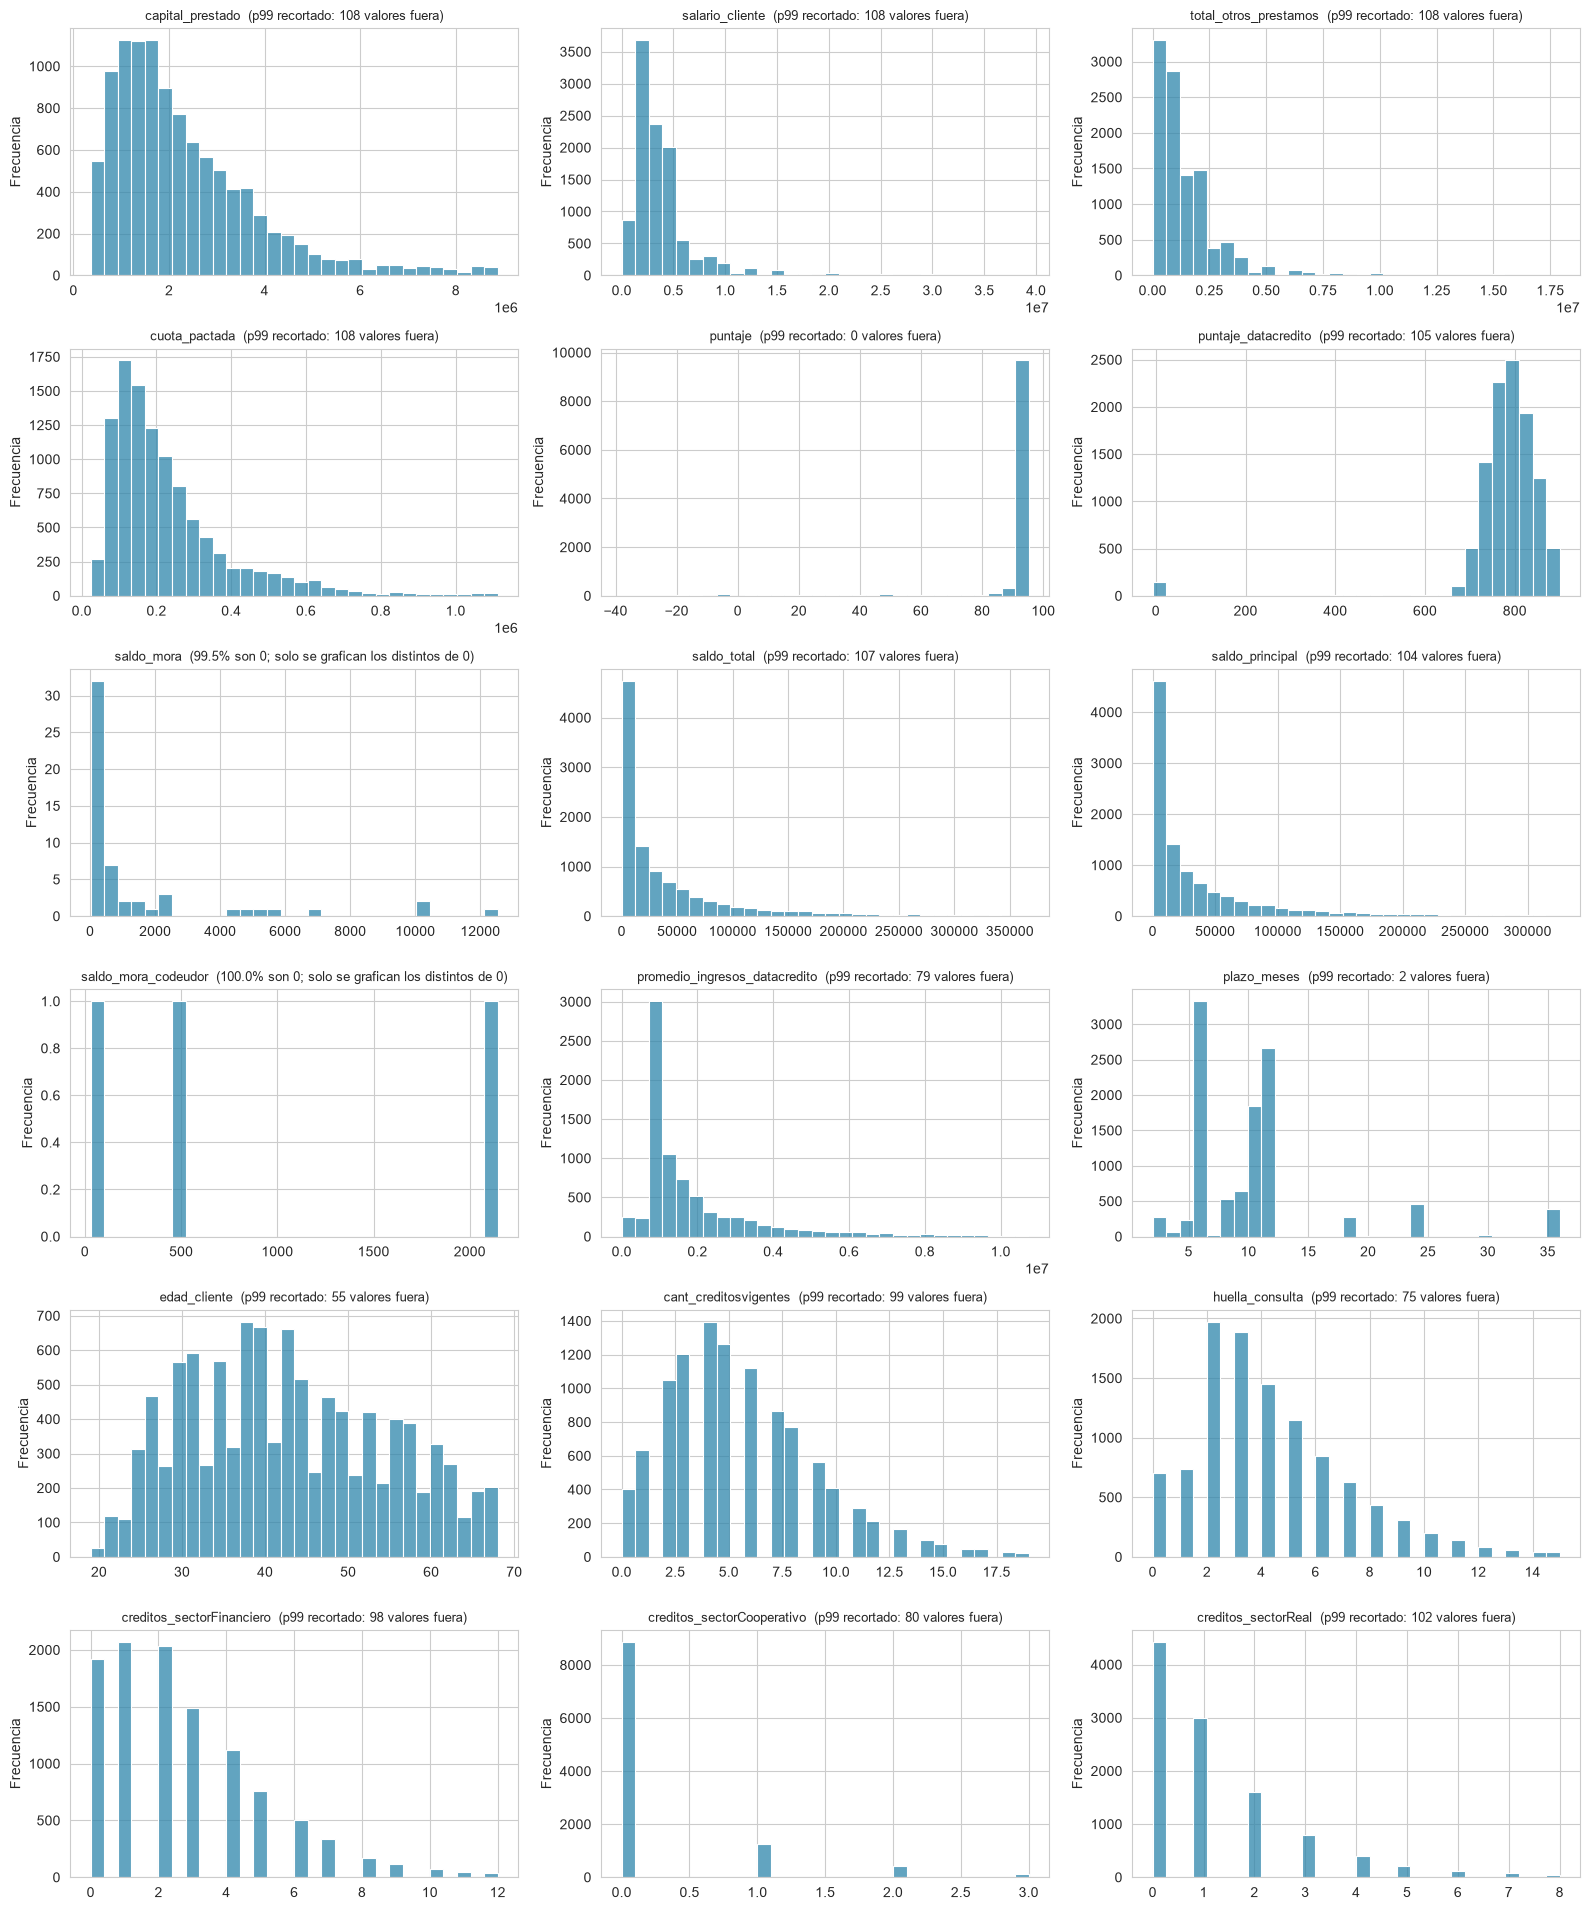

In [13]:
# Histogramas de todas las variables numéricas, recortados en el percentil 99
n_cols = 3
n_filas = int(np.ceil(len(variables_numericas) / n_cols))
fig, axes = plt.subplots(n_filas, n_cols, figsize=(16, 3.2 * n_filas))
axes = axes.flatten()

for i, col in enumerate(variables_numericas):
    serie = data[col].dropna()
    pct_ceros = (serie == 0).mean() * 100
    if pct_ceros >= 90:
        # Variable casi toda en cero: se grafican solo los valores distintos de cero y se informa el % de ceros
        serie = serie[serie != 0]
        titulo = f'{col}  ({pct_ceros:.1f}% son 0; solo se grafican los distintos de 0)'
    else:
        limite = serie.quantile(0.99)
        n_fuera = int((serie > limite).sum())
        serie = serie[serie <= limite]
        titulo = f'{col}  (p99 recortado: {n_fuera} valores fuera)'
    sns.histplot(serie, bins=30, color=COLOR_PAGO, ax=axes[i])
    axes[i].set_title(titulo, fontsize=9)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia')

# Se ocultan los paneles sobrantes de la grilla
for j in range(len(variables_numericas), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

**Interpretación del análisis univariable (numéricas)**

- **Montos y saldos** (`capital_prestado`, `cuota_pactada`, `salario_cliente`, `total_otros_prestamos`, `saldo_total`, `saldo_principal`, `promedio_ingresos_datacredito`): distribuciones **muy asimétricas hacia la derecha** (asimetría entre 3,7 y 43,8) con la media muy por encima de la mediana. Por ejemplo, el salario medio es 17,2 millones y la mediana 3 millones; la diferencia la producen pocos valores extremos (sección 8). Para modelos sensibles a la escala será necesario transformarlas (por ejemplo, con logaritmo).
- **`saldo_mora` y `saldo_mora_codeudor`**: valen 0 en el 99,48 % y el 99,97 % de los registros, respectivamente. Aportan muy poca variabilidad.
- **Puntajes**: `puntaje` toma un único valor (95,23) en el 87,4 % de los créditos; `puntaje_datacredito` se concentra alrededor de 800 (mediana 791, rango intercuartílico 757–825), con un grupo aparte en 0 (145 créditos).
- **Variables de conteo** (`cant_creditosvigentes`, `huella_consulta`, `creditos_sector*`): asimetría moderada a alta, mediana de 5 créditos vigentes y 4 consultas. `creditos_sectorCooperativo` vale 0 en el 82,4 % de los casos.
- **`plazo_meses`**: pocos plazos concentran la cartera: 6 meses (30,9 %), 12 meses (24,7 %) y 10 meses (14,1 %).
- **`edad_cliente`**: entre 19 y 69 años, mediana 42, distribución casi simétrica una vez excluidas las edades inválidas (asimetría 0,27).

**Variables categóricas**

tipo_credito
----------------------------------------
              creditos  porcentaje
tipo_credito                      
4                 7747       71.98
9                 2876       26.72
10                 116        1.08
6                   21        0.20
7                    2        0.02
68                   1        0.01

tipo_laboral
----------------------------------------
               creditos  porcentaje
tipo_laboral                       
Empleado           6754       62.75
Independiente      4009       37.25

tendencia_ingresos
----------------------------------------
                    creditos  porcentaje
tendencia_ingresos                      
Creciente               5294       49.19
Sin dato                2990       27.78
Decreciente             1291       11.99
Estable                 1188       11.04



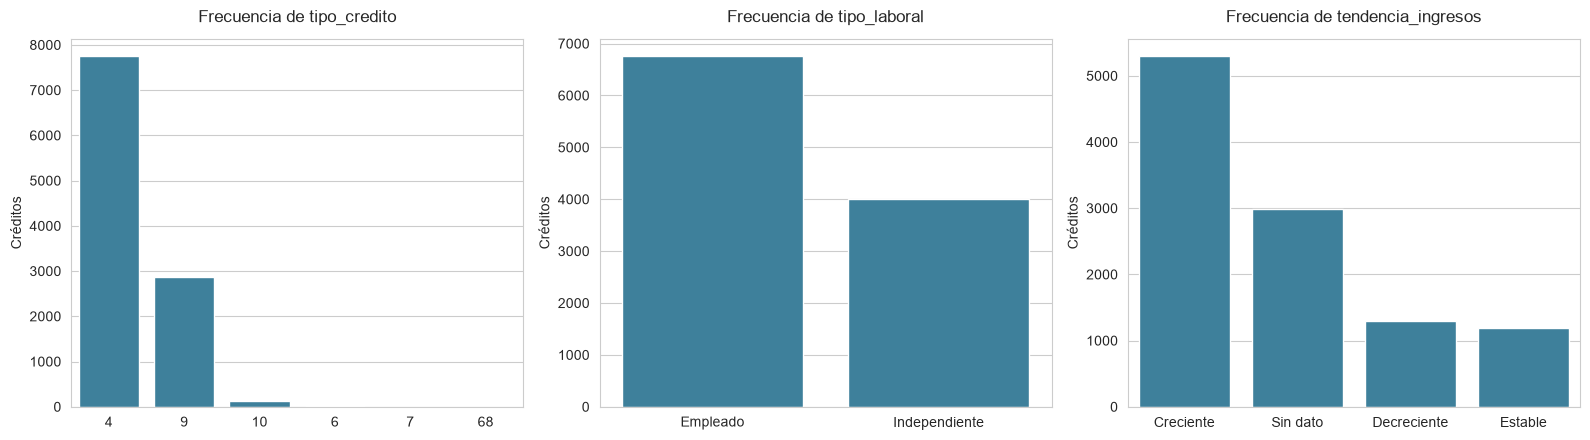

In [14]:
# Frecuencias de las categóricas (los nulos se muestran como "Sin dato")
for col in categoricas:
    tabla = data[col].fillna('Sin dato').value_counts()
    tabla = pd.DataFrame({'creditos': tabla, 'porcentaje': (tabla / len(data) * 100).round(2)})
    print(f'{col}')
    print('-' * 40)
    print(tabla.to_string())
    print()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, categoricas):
    orden = data[col].fillna('Sin dato').astype(str).value_counts().index
    sns.countplot(x=data[col].fillna('Sin dato').astype(str), order=orden, color=COLOR_PAGO, ax=ax)
    ax.set_title(f'Frecuencia de {col}', pad=12)
    ax.set_xlabel('')
    ax.set_ylabel('Créditos')
plt.tight_layout()
plt.show()

**Interpretación del análisis univariable (categóricas)**

- **`tipo_credito`**: dos productos concentran el 98,7 % de la cartera: el código 4 (71,98 %) y el 9 (26,72 %). El 10 (1,08 %) y el 6 (0,20 %) son marginales, y los códigos 7 y 68 suman 3 registros.
- **`tipo_laboral`**: 62,75 % empleados y 37,25 % independientes.
- **`tendencia_ingresos`**: "Creciente" es la categoría dominante (49,19 % del total; 68,1 % de los créditos con dato válido), seguida de "Sin dato" (27,78 %), "Decreciente" (11,99 %) y "Estable" (11,04 %).

### 7.2 Análisis bivariable (cada variable frente a `Pago_atiempo`)

**Categóricas vs. objetivo.** Se muestra la **tasa de no pago** de cada categoría, con la cantidad de créditos (`n`) entre paréntesis: una tasa calculada sobre pocos casos no es confiable.

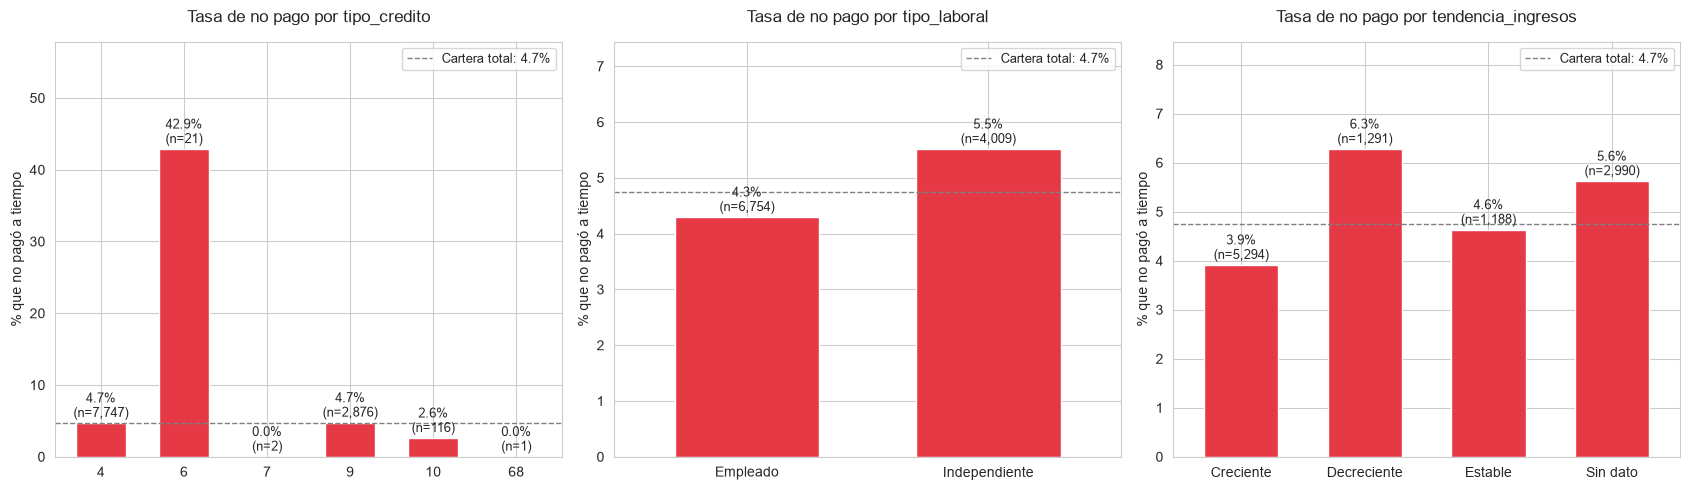

In [15]:
# Tasa de no pago por categoría
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, col in zip(axes, categoricas):
    agrupado = data.assign(**{col: data[col].fillna('Sin dato').astype(str)}).groupby(col)['Pago_atiempo']
    tasa_no_pago = (1 - agrupado.mean()) * 100
    n = agrupado.size()
    if col == 'tipo_credito':   # orden numérico de los códigos (si no, '10' queda antes que '4')
        orden = sorted(tasa_no_pago.index, key=int)
        tasa_no_pago, n = tasa_no_pago[orden], n[orden]
    tasa_no_pago.plot(kind='bar', color=COLOR_NO_PAGO, width=0.6, ax=ax, label='_nolegend_')
    ax.set_title(f'Tasa de no pago por {col}', pad=14)
    ax.set_ylabel('% que no pagó a tiempo')
    ax.set_xlabel('')
    ax.set_ylim(0, tasa_no_pago.max() * 1.35)
    ax.tick_params(axis='x', rotation=0)
    for j, (cat, v) in enumerate(tasa_no_pago.items()):
        ax.text(j, v + tasa_no_pago.max() * 0.02, f'{v:.1f}%\n(n={n[cat]:,})', ha='center', fontsize=9)

# Línea de referencia: tasa de no pago de toda la cartera
tasa_global = (1 - data['Pago_atiempo'].mean()) * 100
for ax in axes:
    ax.axhline(tasa_global, color='gray', linestyle='--', linewidth=1, label=f'Cartera total: {tasa_global:.1f}%')
    ax.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

**Interpretación (categóricas vs. objetivo)**

- **`tipo_credito`**: los códigos 4 y 9 tienen la misma tasa de no pago (4,7 %, igual a la de la cartera) y el 10 tiene 2,6 % (n = 116). El código **6 muestra 42,9 % (9 de 21 créditos)**: una diferencia enorme pero sobre muy pocos casos; es una señal para validar, no una conclusión firme. Los códigos 7 y 68 (n = 2 y 1) no permiten ninguna conclusión.
- **`tipo_laboral`**: los independientes tienen una tasa de no pago de 5,5 % frente a 4,3 % de los empleados (1,3 veces más).
- **`tendencia_ingresos`**: la tasa ordena de forma coherente con la intuición: "Decreciente" 6,3 %, "Sin dato" 5,6 %, "Estable" 4,6 % y "Creciente" 3,9 %.
- **Lectura general**: salvo el código 6, las diferencias son de uno o dos puntos porcentuales. Con solo 511 no pagos, diferencias de décimas pueden ser azar; ninguna categoría por sí sola separa bien a los grupos.

**Numéricas vs. objetivo.** Se comparan las distribuciones de los dos grupos con histogramas (cada grupo normalizado por separado: el eje vertical es la proporción de créditos del grupo en cada tramo, porque hay 20 veces más créditos pagados que no pagados) y una tabla de medianas.

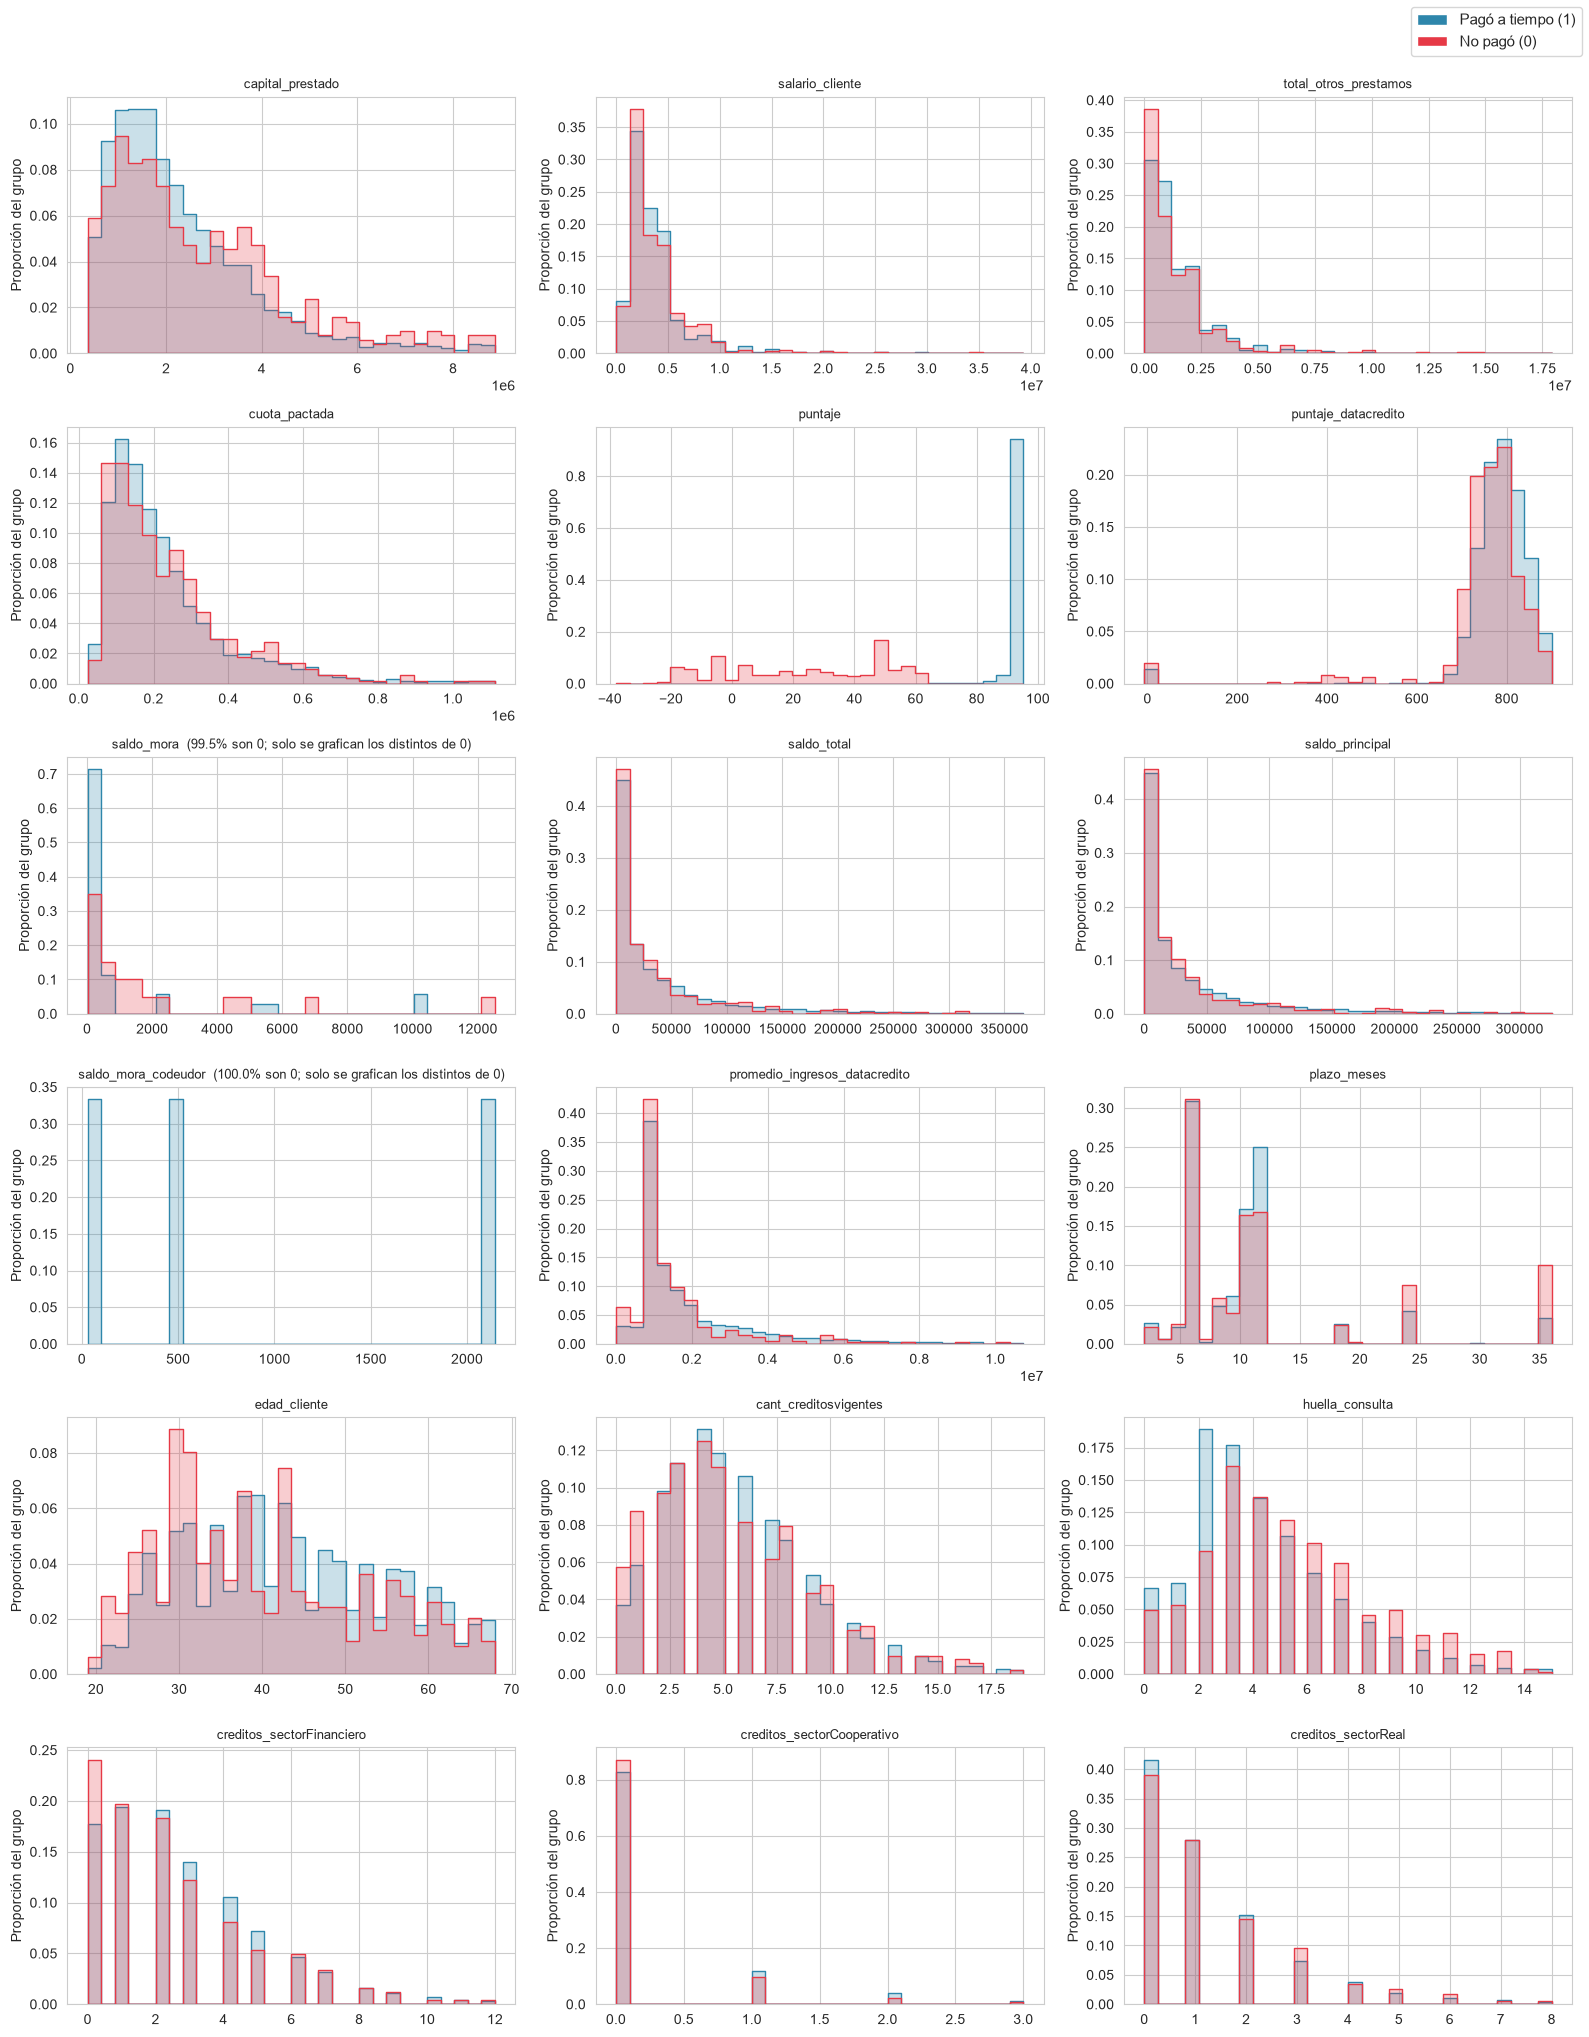

In [16]:
# Distribuciones por grupo (densidad, recortadas en el percentil 99)
n_cols = 3
n_filas = int(np.ceil(len(variables_numericas) / n_cols))
fig, axes = plt.subplots(n_filas, n_cols, figsize=(16, 3.4 * n_filas))
axes = axes.flatten()

for i, col in enumerate(variables_numericas):
    subconjunto = data[[col, 'Pago_atiempo']].dropna()
    pct_ceros = (subconjunto[col] == 0).mean() * 100
    if pct_ceros >= 90:
        subconjunto = subconjunto[subconjunto[col] != 0]   # solo valores distintos de cero
        titulo = f'{col}  ({pct_ceros:.1f}% son 0; solo se grafican los distintos de 0)'
    else:
        subconjunto = subconjunto[subconjunto[col] <= subconjunto[col].quantile(0.99)]
        titulo = col
    # stat='probability' + common_norm=False: cada grupo suma 1 por separado.
    # Sin esto, el grupo "no pagó" (5%) se vería casi plano frente al grupo "pagó" (95%).
    sns.histplot(data=subconjunto, x=col, hue='Pago_atiempo', stat='probability', common_norm=False,
                 element='step', bins=30, palette=PALETA, legend=False, ax=axes[i])
    axes[i].set_title(titulo, fontsize=9)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Proporción del grupo')

for j in range(len(variables_numericas), len(axes)):
    axes[j].axis('off')

fig.legend(handles=[Patch(facecolor=COLOR_PAGO, label='Pagó a tiempo (1)'),
                    Patch(facecolor=COLOR_NO_PAGO, label='No pagó (0)')],
           loc='upper right', fontsize=11, frameon=True)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

In [17]:
# Medianas por grupo (la mediana es robusta a los valores extremos)
medianas = data.groupby('Pago_atiempo')[variables_numericas].median().T
medianas.columns = ['mediana_no_pago (0)', 'mediana_pago (1)']
medianas

,mediana_no_pago (0),mediana_pago (1)
capital_prestado,"2,268,000.00","1,908,446.40"
salario_cliente,"3,000,000.00","3,000,000.00"
total_otros_prestamos,"900,000.00","1,000,000.00"
cuota_pactada,"199,002.00","182,576.00"
puntaje,25.42,95.23
puntaje_datacredito,768.00,792.00
saldo_mora,0.00,0.00
saldo_total,"14,518.50","16,308.00"
saldo_principal,"13,110.00","14,492.50"
saldo_mora_codeudor,0.00,0.00


In [18]:
# Poder discriminante de cada variable por sí sola: AUC univariable.
# AUC = 0.5 -> la variable no separa a los grupos; 1.0 (o 0.0) -> los separa por completo.
# Los nulos se completan con la mediana solo para esta medición exploratoria.
y = data['Pago_atiempo']
filas = []
for col in variables_numericas:
    x = data[col].fillna(data[col].median())
    auc = roc_auc_score(y, x)
    filas.append({
        'variable': col,
        'AUC': auc,
        'AUC_sin_signo': max(auc, 1 - auc),   # fuerza de la separación sin importar la dirección
        'relacion': 'a mayor valor, más pago' if auc >= 0.5 else 'a mayor valor, menos pago',
    })

auc_univariable = pd.DataFrame(filas).sort_values('AUC_sin_signo', ascending=False).reset_index(drop=True)
auc_univariable

,variable,AUC,AUC_sin_signo,relacion
0,puntaje,1.00,1.00,"a mayor valor, más pago"
1,puntaje_datacredito,0.62,0.62,"a mayor valor, más pago"
2,huella_consulta,0.40,0.60,"a mayor valor, menos pago"
3,edad_cliente,0.57,0.57,"a mayor valor, más pago"
4,capital_prestado,0.44,0.56,"a mayor valor, menos pago"
5,promedio_ingresos_datacredito,0.55,0.55,"a mayor valor, más pago"
6,creditos_sectorFinanciero,0.54,0.54,"a mayor valor, más pago"
7,total_otros_prestamos,0.54,0.54,"a mayor valor, más pago"
8,creditos_sectorReal,0.48,0.52,"a mayor valor, menos pago"
9,creditos_sectorCooperativo,0.52,0.52,"a mayor valor, más pago"


**Interpretación (numéricas vs. objetivo)**

- **`puntaje`** separa por completo a los dos grupos (AUC = 1,0000). Se analiza en la sección 9.
- **El resto de las variables tiene poder discriminante bajo.** La mejor es `puntaje_datacredito` (AUC 0,623), seguida de `huella_consulta` (0,598; más consultas, menos pago), `edad_cliente` (0,574; los mayores pagan más), `capital_prestado` (0,557; montos mayores, menos pago) y `promedio_ingresos_datacredito` (0,548). Las demás están entre 0,50 y 0,54: sin señal individual apreciable.
- **Medianas por grupo**: los créditos no pagados tienen montos mayores (capital 2,27 vs 1,91 millones; cuota 199 mil vs 183 mil), clientes más jóvenes (37 vs 42 años), más consultas crediticias (5 vs 4) y menores ingresos promedio (1,05 vs 1,21 millones). Las direcciones son coherentes entre sí, pero las diferencias son moderadas.
- **Implicación:** salvo `puntaje`, la señal disponible en la base es débil, por lo que se anticipa un rendimiento modesto de los modelos que no la usen. Es una limitación de los datos (base sintética), no del modelado.

### 7.3 Análisis multivariable

**Correlaciones.** Se usa la correlación de **Spearman** (basada en rangos) en lugar de Pearson porque casi todas las variables tienen colas muy largas y valores extremos, que distorsionan a Pearson.

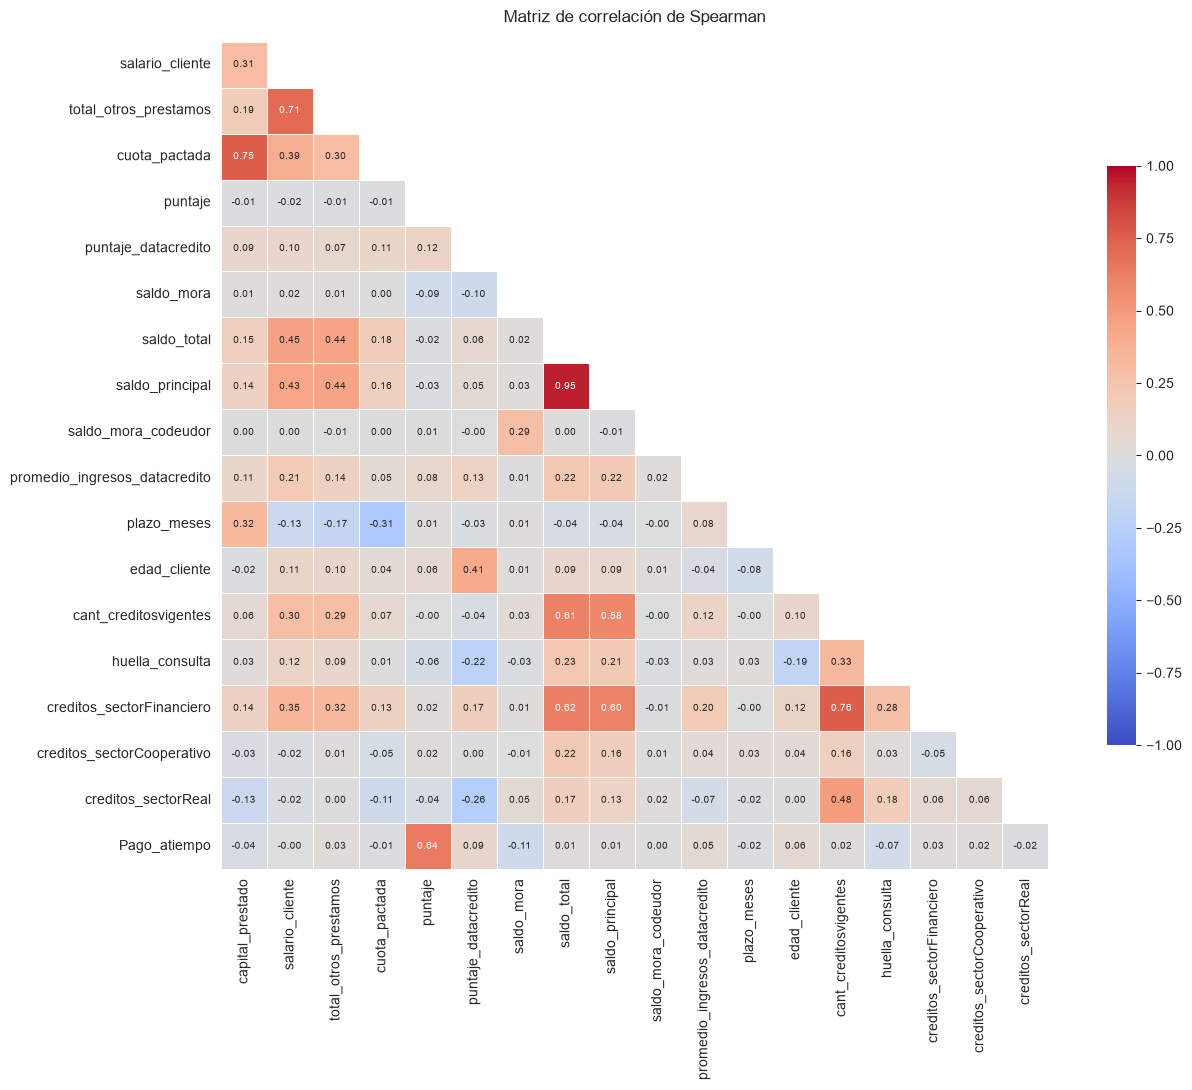

Pares de predictoras con |correlación| >= 0.5:


,variable_1,variable_2,correlacion
0,saldo_principal,saldo_total,0.95
1,creditos_sectorFinanciero,cant_creditosvigentes,0.76
2,cuota_pactada,capital_prestado,0.75
3,total_otros_prestamos,salario_cliente,0.71
4,creditos_sectorFinanciero,saldo_total,0.62
5,cant_creditosvigentes,saldo_total,0.61
6,creditos_sectorFinanciero,saldo_principal,0.60
7,cant_creditosvigentes,saldo_principal,0.58


In [19]:
# Matriz de correlación de Spearman (numéricas + objetivo)
vars_corr = variables_numericas + ['Pago_atiempo']
corr = data[vars_corr].corr(method='spearman')

# Se quitan la primera fila y la última columna: quedarían vacías al ocultar el triángulo superior
corr_visible = corr.iloc[1:, :-1]
mascara = np.triu(np.ones_like(corr_visible, dtype=bool), k=1)   # se oculta el triángulo superior (la matriz es simétrica)

with sns.axes_style('white'):
    fig, ax = plt.subplots(figsize=(14, 11))
    sns.heatmap(corr_visible, mask=mascara, annot=True, fmt='.2f', annot_kws={'size': 7}, cmap='coolwarm',
                center=0, vmin=-1, vmax=1, square=True, linewidths=0.4, linecolor='white',
                cbar_kws={'shrink': 0.7}, ax=ax)
    ax.set_title('Matriz de correlación de Spearman', pad=14)
    plt.tight_layout()
    plt.show()

# Pares de variables predictoras más correlacionados (en valor absoluto)
pares = corr.drop(index='Pago_atiempo', columns='Pago_atiempo').where(np.tril(np.ones(corr.shape), k=-1)[:-1, :-1].astype(bool))
pares = pares.stack().rename('correlacion').reset_index()
pares.columns = ['variable_1', 'variable_2', 'correlacion']
pares['abs'] = pares['correlacion'].abs()
print('Pares de predictoras con |correlación| >= 0.5:')
pares[pares['abs'] >= 0.5].sort_values('abs', ascending=False).drop(columns='abs').reset_index(drop=True)

In [20]:
# Correlación de cada variable con el objetivo
corr[['Pago_atiempo']].drop(index='Pago_atiempo').sort_values('Pago_atiempo', key=abs, ascending=False)

,Pago_atiempo
puntaje,0.64
saldo_mora,-0.11
puntaje_datacredito,0.09
huella_consulta,-0.07
edad_cliente,0.06
promedio_ingresos_datacredito,0.05
capital_prestado,-0.04
creditos_sectorFinanciero,0.03
total_otros_prestamos,0.03
creditos_sectorCooperativo,0.02


**Multicolinealidad (VIF).** El *Variance Inflation Factor* mide cuánto se explica una variable por combinación de las demás. Convencionalmente, VIF > 5 indica redundancia relevante y VIF > 10 redundancia severa. Se calcula sobre los registros completos (sin nulos) y sin la variable objetivo.

In [21]:
# VIF sobre las predictoras numéricas, usando solo filas completas
X_vif = data[variables_numericas].dropna().astype(float)
X_vif = X_vif.assign(const=1.0)   # el VIF requiere un término constante en el cálculo

vif = pd.DataFrame({
    'variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
})
vif = vif[vif['variable'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)

print(f'Filas completas utilizadas: {len(X_vif):,} de {len(data):,}')
display(vif)

Filas completas utilizadas: 7,673 de 10,763


,variable,VIF
0,cant_creditosvigentes,10.05
1,creditos_sectorFinanciero,7.39
2,capital_prestado,5.35
3,cuota_pactada,5.06
4,creditos_sectorReal,3.12
5,plazo_meses,2.59
6,saldo_principal,2.47
7,saldo_total,2.05
8,puntaje_datacredito,1.57
9,creditos_sectorCooperativo,1.37


**Interpretación (correlación y multicolinealidad)**

- **Redundancia entre predictoras**: `saldo_total` y `saldo_principal` (Spearman 0,95), `creditos_sectorFinanciero` y `cant_creditosvigentes` (0,76), `capital_prestado` y `cuota_pactada` (0,75), y `total_otros_prestamos` y `salario_cliente` (0,71).
- **Relación con el objetivo**: solo `puntaje` correlaciona de forma relevante (0,64). Todas las demás tienen |ρ| ≤ 0,11 (la mayor es `saldo_mora`, −0,11).
- **VIF**: `cant_creditosvigentes` (10,05), `creditos_sectorFinanciero` (7,39), `capital_prestado` (5,35) y `cuota_pactada` (5,06) superan el umbral de 5; el resto está por debajo. Es esperable: la cantidad de créditos vigentes está relacionada con los créditos por sector.
- **Nota metodológica**: el VIF se calcula sobre los valores originales, sensibles a los extremos. Por eso `saldo_total` y `saldo_principal` muestran VIF bajos (2,05 y 2,47) aunque su correlación de rangos es 0,95: la correlación lineal entre ambas es menor (Pearson 0,74). Conviene recalcular el VIF después de tratar los valores extremos.
- **Decisión**: para modelos lineales se eliminarán o combinarán las variables redundantes; para árboles y boosting la multicolinealidad no es crítica.

**Cruces entre variables categóricas.** Se combinan variables para ver si el riesgo cambia según el perfil. Se informa `n` en cada celda para no interpretar tasas sobre muy pocos casos.

In [22]:
# Tasa de no pago por tipo_laboral x tipo_credito
cruce_1 = data.groupby(['tipo_laboral', 'tipo_credito'])['Pago_atiempo'].agg(
    n='size', tasa_no_pago=lambda s: (1 - s.mean()) * 100).round(2)
print('TIPO LABORAL x TIPO DE CRÉDITO')
display(cruce_1)

# Tasa de no pago por tendencia_ingresos x tipo_laboral
cruce_2 = data.assign(tendencia_ingresos=data['tendencia_ingresos'].fillna('Sin dato')).groupby(
    ['tendencia_ingresos', 'tipo_laboral'])['Pago_atiempo'].agg(
    n='size', tasa_no_pago=lambda s: (1 - s.mean()) * 100).round(2)
print('TENDENCIA DE INGRESOS x TIPO LABORAL')
display(cruce_2)

TIPO LABORAL x TIPO DE CRÉDITO


n  tasa_no_pago
tipo_laboral  tipo_credito                    
Empleado      4             5052          4.14
              6               21         42.86
              7                1          0.00
              9             1604          4.36
              10              75          2.67
              68               1          0.00
Independiente 4             2695          5.71
              7                1          0.00
              9             1272          5.19
              10              41          2.44

TENDENCIA DE INGRESOS x TIPO LABORAL


n  tasa_no_pago
tendencia_ingresos tipo_laboral                     
Creciente          Empleado       3843          3.56
                   Independiente  1451          4.82
Decreciente        Empleado        937          5.87
                   Independiente   354          7.34
Estable            Empleado        646          4.49
                   Independiente   542          4.80
Sin dato           Empleado       1328          5.20
                   Independiente  1662          5.96

**Interpretación de los cruces**

- **Tipo laboral × tipo de crédito**: en los dos productos con volumen, los independientes tienen mayor tasa de no pago (código 4: 5,71 % vs 4,14 %; código 9: 5,19 % vs 4,36 %). En el código 10 la relación se invierte levemente (2,44 % vs 2,67 %), con solo 41 y 75 créditos: no es concluyente. El código 6 (42,86 %) está compuesto únicamente por empleados (n = 21).
- **Tendencia de ingresos × tipo laboral**: dentro de cada tendencia, los independientes tienen mayor tasa que los empleados. La mejor combinación es "Creciente + Empleado" (3,56 %) y la peor "Decreciente + Independiente" (7,34 %, unos 26 créditos de 354): una brecha de 2,1 veces.
- **Lectura**: `tipo_laboral` y `tendencia_ingresos` aportan señal moderada y en la misma dirección. Las combinaciones con pocos créditos deben leerse con cautela.

**Relaciones entre variables numéricas.** Pairplot sobre una muestra aleatoria de 3.000 créditos (para que el gráfico sea legible) con las variables más representativas del monto, la cuota, la edad y el historial crediticio.

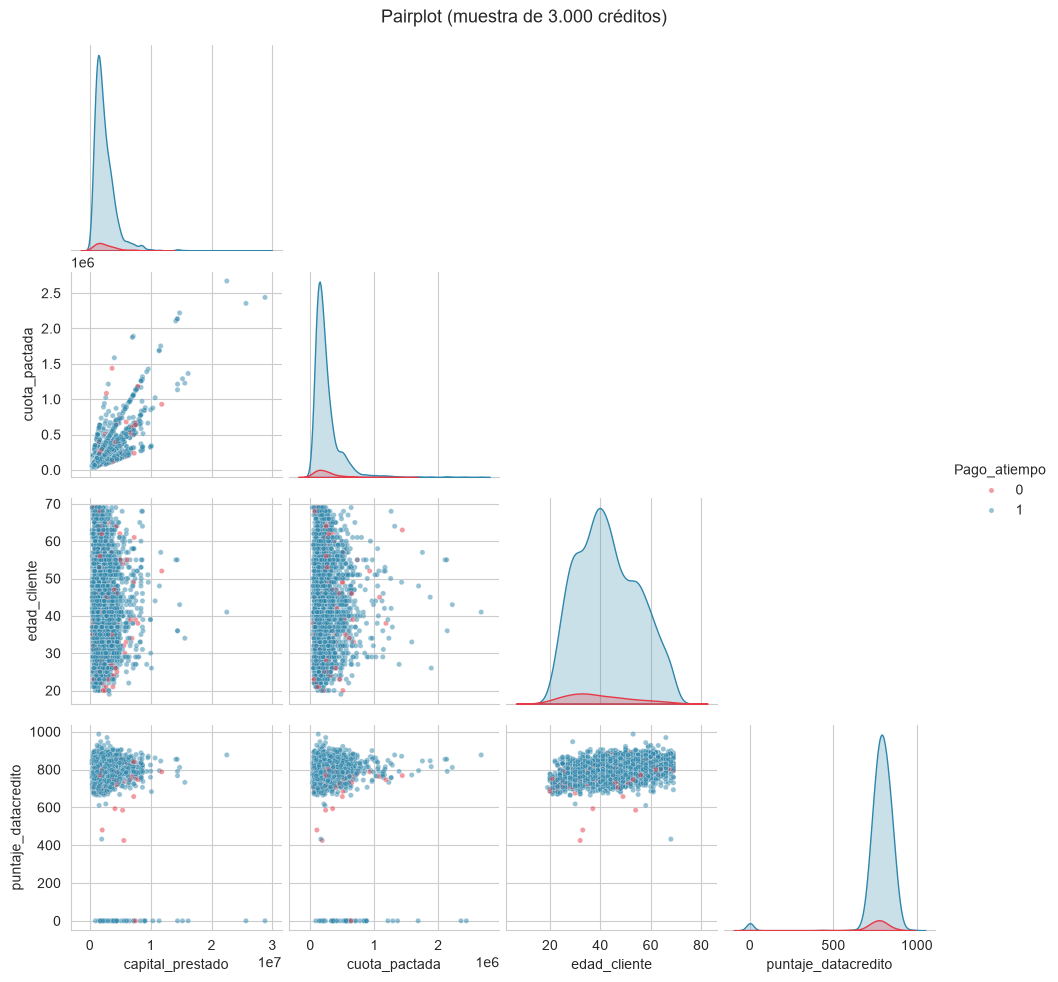

In [23]:
# Muestra reproducible para que el gráfico sea legible y rápido
muestra = data.sample(3000, random_state=RANDOM_STATE)
vars_pair = ['capital_prestado', 'cuota_pactada', 'edad_cliente', 'puntaje_datacredito']

grafico = sns.pairplot(muestra, vars=vars_pair, hue='Pago_atiempo', palette=PALETA, diag_kind='kde',
                       corner=True, height=2.4, plot_kws={'alpha': 0.5, 's': 14})
grafico.fig.suptitle('Pairplot (muestra de 3.000 créditos)', y=1.02, fontsize=13)
plt.show()

**Interpretación del pairplot**

- `capital_prestado` y `cuota_pactada` muestran una relación lineal organizada en varias rectas de distinta pendiente, compatible con créditos de distintos plazos (a igual capital, menor cuota cuanto más largo el plazo).
- En el resto de las parejas no se observa estructura clara, y los créditos no pagados (rojo) se mezclan con los pagados sin formar una región separada. Esto es coherente con el bajo poder discriminante individual de la sección 7.2.
- En `puntaje_datacredito` se ve la franja de valores en 0 (145 créditos, con créditos de ambos grupos) y unos pocos no pagados con puntajes entre 400 y 600.

<a id="8"></a>
## 8. Detección de outliers (IQR)

Se aplica el método del **rango intercuartílico**: un valor es outlier si está por debajo de Q1 − 1,5×IQR o por encima de Q3 + 1,5×IQR. Se informa el resultado para las variables continuas y discretas (las discretas con muy pocos valores distintos se interpretan con cautela). En las variables donde Q1 = Q3 (por ejemplo, saldos mayormente en cero) el método marca como outlier cualquier valor distinto de cero, por eso se informa también el IQR.

In [24]:
def detectar_outliers_iqr(serie):
    '''Devuelve cantidad, porcentaje, IQR y límites de outliers según el método IQR.'''
    serie = serie.dropna()
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((serie < limite_inferior) | (serie > limite_superior)).sum()
    return n_outliers, n_outliers / len(serie) * 100, iqr, limite_inferior, limite_superior


filas = []
for col in variables_numericas:
    n_out, pct_out, iqr, lim_inf, lim_sup = detectar_outliers_iqr(data[col])
    filas.append({'variable': col, 'n_outliers': n_out, 'pct_outliers': round(pct_out, 2),
                  'IQR': iqr, 'limite_inferior': lim_inf, 'limite_superior': lim_sup,
                  'maximo': data[col].max()})

tabla_outliers = pd.DataFrame(filas).sort_values('pct_outliers', ascending=False).reset_index(drop=True)
tabla_outliers

,variable,n_outliers,pct_outliers,IQR,limite_inferior,limite_superior,maximo
0,creditos_sectorCooperativo,1895,17.61,0.00,0.00,0.00,13.00
1,puntaje,1356,12.60,0.00,95.23,95.23,95.23
2,promedio_ingresos_datacredito,784,10.01,"1,306,702.00","-1,034,896.00","4,191,912.00","38,106,581.00"
3,saldo_principal,951,9.18,"44,942.25","-64,723.38","115,045.62","1,562,285.00"
4,saldo_total,970,9.14,"50,084.00","-72,228.00","128,108.00","5,116,066.00"
5,plazo_meses,869,8.07,6.00,-3.00,21.00,90.00
6,cuota_pactada,765,7.11,"166,792.00","-129,146.50","538,021.50","3,816,752.00"
7,salario_cliente,718,6.67,"2,875,808.00","-2,313,712.00","9,189,520.00","22,000,000,000.00"
8,total_otros_prestamos,589,5.47,"1,500,000.00","-1,750,000.00","4,250,000.00","6,787,675,263.00"
9,capital_prestado,550,5.11,"1,860,009.00","-1,565,182.50","5,874,853.50","41,444,152.80"


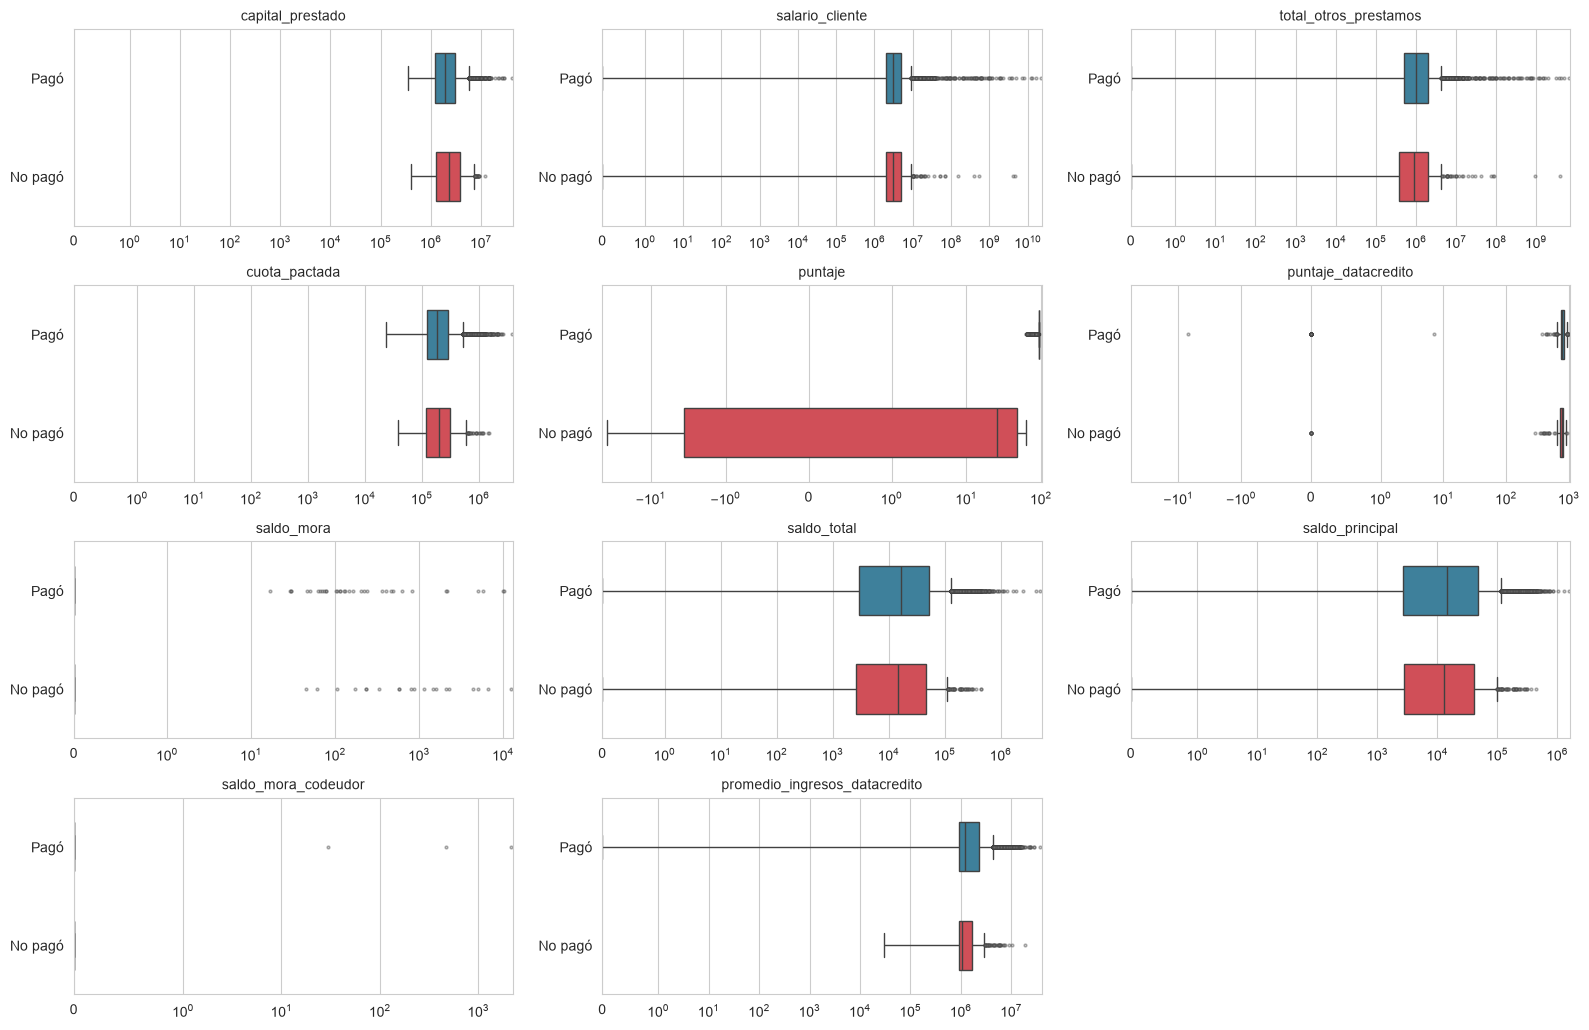

In [25]:
# Boxplots de las variables continuas por grupo de pago. Escala "symlog" (logarítmica que admite ceros):
# sin ella, un solo valor de miles de millones aplasta el resto de la distribución.
etiqueta = data['Pago_atiempo'].map({0: 'No pagó', 1: 'Pagó'})
n_cols = 3
n_filas = int(np.ceil(len(continuas) / n_cols))
fig, axes = plt.subplots(n_filas, n_cols, figsize=(16, 2.6 * n_filas))
axes = axes.flatten()

for i, col in enumerate(continuas):
    sns.boxplot(x=data[col], y=etiqueta, hue=etiqueta, palette={'No pagó': COLOR_NO_PAGO, 'Pagó': COLOR_PAGO},
                orient='h', width=0.5, legend=False, ax=axes[i],
                flierprops=dict(marker='o', markersize=2, markerfacecolor='gray', alpha=0.4))
    axes[i].set_xscale('symlog', linthresh=1)   # lineal cerca de 0, logarítmica para valores grandes
    if data[col].min() >= 0:
        axes[i].set_xlim(left=0)                # variables no negativas: se evita el eje negativo
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

for j in range(len(continuas), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [26]:
# Magnitud de los extremos en salario y otros préstamos: ¿son plausibles?
print('Percentiles de salario_cliente y total_otros_prestamos')
display(data[['salario_cliente', 'total_otros_prestamos']].quantile([0.5, 0.9, 0.99, 0.999, 1.0]))
print(f'Registros con salario_cliente > 100 millones:       {(data["salario_cliente"] > 1e8).sum()}')
print(f'Registros con total_otros_prestamos > 100 millones: {(data["total_otros_prestamos"] > 1e8).sum()}')

Percentiles de salario_cliente y total_otros_prestamos


,salario_cliente,total_otros_prestamos
0.50,"3,000,000.00","1,000,000.00"
0.90,"7,500,000.00","3,000,000.00"
0.99,"39,553,562.18","17,946,060.00"
1.00,"3,343,833,177.20","1,231,431,206.00"
1.00,"22,000,000,000.00","6,787,675,263.00"


Registros con salario_cliente > 100 millones:       74
Registros con total_otros_prestamos > 100 millones: 44


**Interpretación de los outliers**

- **Falsos positivos del método.** `creditos_sectorCooperativo` (17,6 %) y `puntaje` (12,6 %) aparecen con muchos outliers porque su IQR es 0 (casi todos los valores son iguales), y lo mismo ocurre con `saldo_mora` y `saldo_mora_codeudor`. Cuando el IQR es 0, cualquier valor distinto es "outlier": el método sobreestima y no se trata de errores.
- **Valores probablemente erróneos.** `salario_cliente` (718 outliers, 6,67 %) y `total_otros_prestamos` (589, 5,47 %): el percentil 99 del salario es 39,6 millones, el 99,9 es 3.344 millones y el máximo 22.000 millones; 74 salarios y 44 totales de otros préstamos superan los 100 millones, con una mediana de 3 y 1 millón. Magnitudes cientos o miles de veces mayores que la mediana son más compatibles con **errores de carga o de unidades** que con ingresos reales (es una hipótesis, la base no lo documenta).
- **Valores atípicos legítimos.** `capital_prestado` (5,11 %) y `cuota_pactada` (7,11 %) tienen cola derecha larga pero con magnitudes razonables (capital máximo de 41,4 millones). En `plazo_meses` (8,07 %) los plazos de 24 a 36 meses son productos válidos; solo los de 48 y 90 meses (un caso cada uno) son excepcionales.
- **`edad_cliente`** no tiene outliers una vez marcadas como nulas las 150 edades imposibles.
- **Decisión**: no se eliminan outliers en el EDA. En el Avance 2 se tratarán los valores extremos de salario y otros préstamos (acotamiento por percentil o transformación logarítmica), y los modelos de árboles serán menos sensibles a ellos.

<a id="9"></a>
## 9. Posible fuga de información en `puntaje`

En la sección 7 la variable `puntaje` mostró una separación entre los dos grupos mucho mayor que cualquier otra. Antes de usarla en un modelo hay que entender por qué: si el valor se calcula **con posterioridad** al desenlace del crédito (o incorpora su resultado), el modelo "vería" la respuesta y no podría usarse para evaluar solicitantes nuevos. Eso se conoce como **fuga de información** (*data leakage*).

In [27]:
# 1) Distribución de puntaje en cada grupo
print('PUNTAJE POR GRUPO')
print('=' * 70)
display(data.groupby('Pago_atiempo')['puntaje'].describe())

# 2) ¿Los rangos de ambos grupos se solapan?
max_no_pago = data.loc[data['Pago_atiempo'] == 0, 'puntaje'].max()
min_pago = data.loc[data['Pago_atiempo'] == 1, 'puntaje'].min()
print(f'\nMáximo puntaje entre los que NO pagaron: {max_no_pago:.2f}')
print(f'Mínimo puntaje entre los que SÍ pagaron: {min_pago:.2f}')

# 3) Valor más repetido
valor_moda = data['puntaje'].round(4).mode()[0]
es_moda = data['puntaje'].round(4) == valor_moda
print(f'\nValor más repetido: {valor_moda}  ->  {es_moda.mean() * 100:.1f}% de todos los créditos')
print(f'  Entre los que pagaron:    {es_moda[data["Pago_atiempo"] == 1].mean() * 100:.1f}%')
print(f'  Entre los que NO pagaron: {es_moda[data["Pago_atiempo"] == 0].mean() * 100:.1f}%')

# 4) Poder de separación de la variable por sí sola
auc_puntaje = roc_auc_score(data['Pago_atiempo'], data['puntaje'])
print(f'\nAUC de puntaje usada sola: {auc_puntaje:.4f}  (0.5 = no separa nada, 1.0 = separación perfecta)')

PUNTAJE POR GRUPO


,count,mean,std,min,25%,50%,75%,max
Pago_atiempo,,,,,,,,
0,511.00,23.09,26.07,-38.01,-3.59,25.42,47.61,62.67
1,"10,252.00",94.56,2.87,63.81,95.23,95.23,95.23,95.23



Máximo puntaje entre los que NO pagaron: 62.67
Mínimo puntaje entre los que SÍ pagaron: 63.81

Valor más repetido: 95.2278  ->  87.4% de todos los créditos
  Entre los que pagaron:    91.8%
  Entre los que NO pagaron: 0.0%

AUC de puntaje usada sola: 1.0000  (0.5 = no separa nada, 1.0 = separación perfecta)


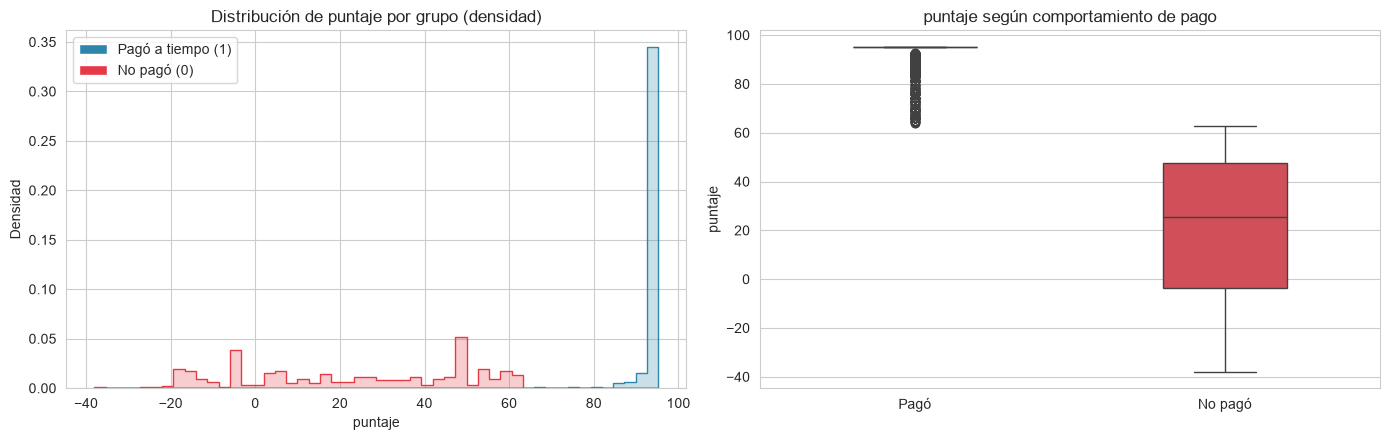

In [28]:
# Visualización: distribución de puntaje por grupo
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(data=data, x='puntaje', hue='Pago_atiempo', palette=PALETA, bins=50,
             element='step', stat='density', common_norm=False, legend=False, ax=axes[0])
axes[0].set_title('Distribución de puntaje por grupo (densidad)')
axes[0].set_ylabel('Densidad')
axes[0].legend(handles=[Patch(facecolor=COLOR_PAGO, label='Pagó a tiempo (1)'),
                        Patch(facecolor=COLOR_NO_PAGO, label='No pagó (0)')], loc='upper left')

sns.boxplot(x=etiqueta, y=data['puntaje'], hue=etiqueta, palette={'No pagó': COLOR_NO_PAGO, 'Pagó': COLOR_PAGO},
            legend=False, width=0.4, ax=axes[1])
axes[1].set_title('puntaje según comportamiento de pago')
axes[1].set_xlabel('')

plt.tight_layout()
plt.show()

In [29]:
# Contraste con la otra variable de puntaje (puntaje_datacredito) y con la correlación entre ambas
print(f'AUC de puntaje_datacredito sola: {roc_auc_score(data["Pago_atiempo"], data["puntaje_datacredito"].fillna(data["puntaje_datacredito"].median())):.4f}')
print(f'Correlación de Spearman puntaje vs puntaje_datacredito: {data[["puntaje", "puntaje_datacredito"]].corr(method="spearman").iloc[0, 1]:.3f}')

AUC de puntaje_datacredito sola: 0.6229
Correlación de Spearman puntaje vs puntaje_datacredito: 0.120


**Conclusión: `puntaje` presenta fuga de información y no debe usarse como variable predictora.**

La evidencia es de tres tipos:

1. **Separación perfecta.** Ningún crédito no pagado supera 62,67 y ningún crédito pagado baja de 63,81: los rangos no se solapan. El AUC de la variable usada sola es 1,0000, es decir, un "modelo" con solo `puntaje` clasificaría sin errores a los 10.763 créditos.
2. **Valor constante.** El 91,8 % de los créditos pagados tiene exactamente 95,2278 y ningún crédito no pagado lo tiene (0 %). Un puntaje real no concentra casi todo un grupo en un único valor idéntico; es más compatible con un valor tope asignado a quien no tuvo atrasos.
3. **Contraste con `puntaje_datacredito`.** El puntaje externo separa poco (AUC 0,623) y su correlación con `puntaje` es de apenas 0,12: no miden lo mismo.

**Interpretación.** `puntaje` parece calculado o actualizado **después** de conocerse el comportamiento de pago (por ejemplo, un puntaje de comportamiento que incorpora los atrasos). No se puede confirmar sin un diccionario de variables. Un modelo que lo use mostraría métricas casi perfectas pero sería inútil para evaluar solicitantes nuevos, porque al momento de otorgar el crédito ese valor no existe.

**Decisión.** Se excluye `puntaje` del modelo de producción. En el Avance 2 se entrenará una versión con y otra sin esta variable únicamente para documentar el efecto. **Pregunta pendiente para el profesor:** ¿`puntaje` está disponible en el momento de otorgar el crédito?

<a id="10"></a>
## 10. Análisis temporal de `fecha_prestamo`

La fecha del préstamo permite ver cómo cambia la cartera en el tiempo. Es relevante por dos motivos: afecta la **forma de dividir** los datos para entrenar y evaluar un modelo, y es la base natural para el **monitoreo de deriva de datos** (*data drift*) del Avance 3.

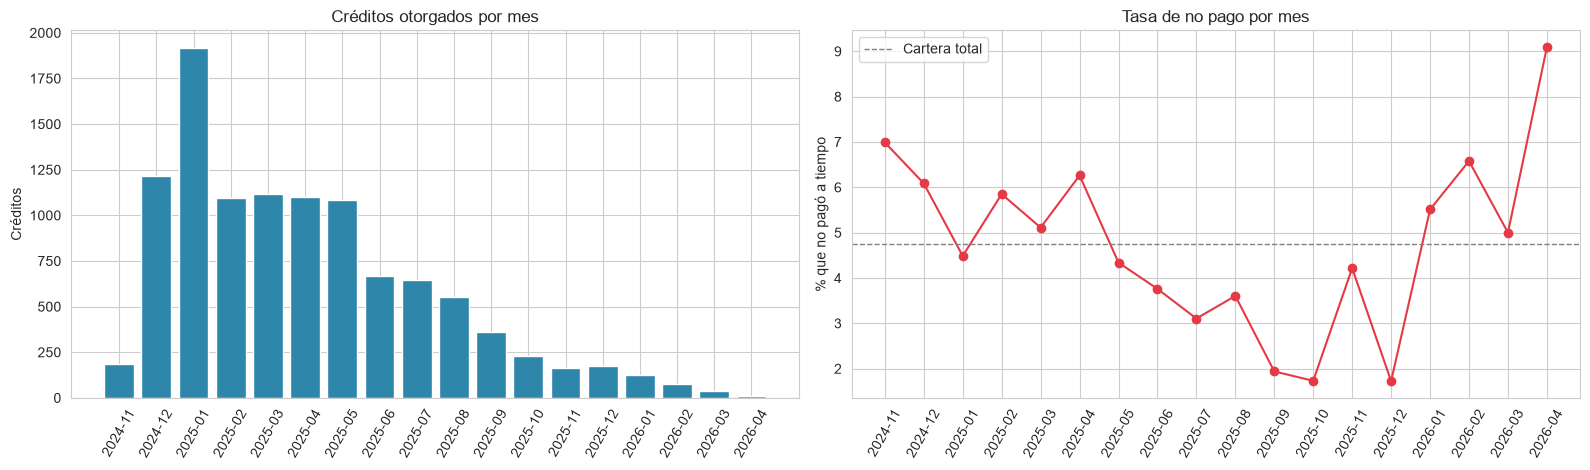

fecha_prestamo,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04
n_creditos,186.00,"1,216.00","1,917.00","1,094.00","1,115.00","1,102.00","1,083.00",665.00,644.00,555.00,361.00,231.00,166.00,174.00,127.00,76.00,40.00,11.00
tasa_no_pago,6.99,6.09,4.49,5.85,5.11,6.26,4.34,3.76,3.11,3.60,1.94,1.73,4.22,1.72,5.51,6.58,5.00,9.09


In [30]:
# Créditos y tasa de no pago por mes de otorgamiento
periodo = data['fecha_prestamo'].dt.to_period('M')
mensual = data.groupby(periodo)['Pago_atiempo'].agg(
    n_creditos='size', tasa_no_pago=lambda s: (1 - s.mean()) * 100)
mensual.index = mensual.index.astype(str)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

axes[0].bar(mensual.index, mensual['n_creditos'], color=COLOR_PAGO)
axes[0].set_title('Créditos otorgados por mes')
axes[0].set_ylabel('Créditos')
axes[0].tick_params(axis='x', rotation=60)

axes[1].plot(mensual.index, mensual['tasa_no_pago'], marker='o', color=COLOR_NO_PAGO)
axes[1].axhline((1 - data['Pago_atiempo'].mean()) * 100, color='gray', linestyle='--', linewidth=1, label='Cartera total')
axes[1].set_title('Tasa de no pago por mes')
axes[1].set_ylabel('% que no pagó a tiempo')
axes[1].tick_params(axis='x', rotation=60)
axes[1].legend()

plt.tight_layout()
plt.show()

mensual.round(2).T

In [31]:
# Perfil de la cartera al inicio y al final del período: ¿cambian las variables en el tiempo?
# Se compara el primer y el último tercio de los créditos ordenados por fecha.
ordenado = data.sort_values('fecha_prestamo')
tercio = len(ordenado) // 3
primero, ultimo = ordenado.iloc[:tercio], ordenado.iloc[-tercio:]

comparacion_periodos = pd.DataFrame({
    'mediana_primer_tercio': primero[variables_numericas].median(),
    'mediana_ultimo_tercio': ultimo[variables_numericas].median(),
})
comparacion_periodos['variacion_%'] = ((comparacion_periodos['mediana_ultimo_tercio'] /
                                        comparacion_periodos['mediana_primer_tercio'] - 1) * 100).replace([np.inf, -np.inf], np.nan)
print(f'Primer tercio: {primero["fecha_prestamo"].min():%d/%m/%Y} a {primero["fecha_prestamo"].max():%d/%m/%Y}')
print(f'Último tercio: {ultimo["fecha_prestamo"].min():%d/%m/%Y} a {ultimo["fecha_prestamo"].max():%d/%m/%Y}')
comparacion_periodos.round(2)

Primer tercio: 26/11/2024 a 07/02/2025
Último tercio: 16/05/2025 a 26/04/2026


,mediana_primer_tercio,mediana_ultimo_tercio,variacion_%
capital_prestado,"1,923,600.00","2,021,323.20",5.08
salario_cliente,"3,000,000.00","3,000,000.00",0.00
total_otros_prestamos,"850,000.00","1,000,000.00",17.65
cuota_pactada,"166,408.00","205,841.00",23.70
puntaje,95.23,95.23,0.00
puntaje_datacredito,792.00,789.00,-0.38
saldo_mora,0.00,0.00,NaN
saldo_total,"14,167.00","16,932.00",19.52
saldo_principal,"12,238.00","15,241.00",24.54
saldo_mora_codeudor,0.00,0.00,NaN


**Interpretación del análisis temporal**

- **Volumen.** Los créditos otorgados por mes pasan de 1.917 en enero de 2025 a 11 en abril de 2026, con una caída sostenida desde mayo de 2025 (1.083). La base no documenta la causa.
- **Tasa de no pago.** Varía entre 1,7 % y 9,1 % por mes, pero con meses de entre 11 y 174 créditos las tasas mensuales son inestables: el 9,1 % de abril de 2026 corresponde a 1 crédito de 11. No se interpreta una tendencia a partir de estos valores.
- **Cambio de perfil de la cartera.** Entre el primer tercio (26/11/2024 – 07/02/2025) y el último (16/05/2025 – 26/04/2026) cambian las medianas de `plazo_meses` (de 12 a 8, −33 %), `huella_consulta` (de 3 a 4, +33 %), `cuota_pactada` (+23,7 %), `saldo_principal` (+24,5 %), `saldo_total` (+19,5 %) y `total_otros_prestamos` (+17,6 %); los ingresos y los puntajes casi no cambian. En las variables discretas (plazo y consultas) la mediana salta de a pasos, por lo que se leen con cautela.
- **Implicaciones.** El perfil de la cartera **cambió con el tiempo**: es un punto de partida natural para el análisis de *data drift* del Avance 3 (comparar un período inicial con uno reciente) y obliga a evaluar si conviene una partición temporal además de la aleatoria estratificada.

<a id="11"></a>
## 11. Hallazgos y decisiones para el Avance 2

### 11.1 Hallazgos principales

1. **Desbalanceo fuerte**: 95,25 % pagó a tiempo y 4,75 % no (511 créditos).
2. **`puntaje` tiene fuga de información** (AUC 1,0000; valor constante en 91,8 % de los pagados y en ninguno de los no pagados).
3. **Excluido `puntaje`, la señal es débil**: el mejor AUC individual es 0,623 (`puntaje_datacredito`). Los factores de riesgo observados son: tipo de crédito 6 (con solo 21 casos), tendencia de ingresos decreciente, trabajadores independientes, clientes más jóvenes, más consultas crediticias y montos mayores.
4. **Calidad de datos**: 7 columnas con nulos (dos con ~27 %, en las mismas filas), 58 valores inválidos en `tendencia_ingresos`, 150 edades imposibles, 145 puntajes de datacrédito en 0 y valores extremos de salario y otros préstamos.
5. **Redundancia** entre `saldo_total` y `saldo_principal`, entre `cant_creditosvigentes` y los créditos por sector, y entre `capital_prestado` y `cuota_pactada`.
6. **El perfil de la cartera cambió en el tiempo** (plazos más cortos, más consultas, cuotas y saldos mayores).
7. **Los independientes tienen más no pago que los empleados** en los dos productos con volumen y dentro de cada tendencia de ingresos, salvo en el código 10 (muestra chica); la combinación de peor desempeño es "Decreciente + Independiente" (ver 11.2).

### 11.2 Segmentos de riesgo e implicaciones de negocio

Ordenados por tasa de no pago (cruce de `tendencia_ingresos` × `tipo_laboral`, sección 7.3). La brecha entre extremos es de 2,1 veces, mayor que la de cualquier variable por separado.

| Segmento | Créditos | Tasa de no pago | Lectura |
|---|---|---|---|
| Creciente + Empleado | 3.843 | 3,56 % | Menor riesgo |
| Estable + Empleado | 646 | 4,49 % | Riesgo bajo |
| Estable + Independiente | 542 | 4,80 % | Riesgo bajo |
| Creciente + Independiente | 1.451 | 4,82 % | Riesgo bajo |
| Sin dato + Empleado | 1.328 | 5,20 % | Riesgo medio |
| Decreciente + Empleado | 937 | 5,87 % | Riesgo medio-alto |
| Sin dato + Independiente | 1.662 | 5,96 % | Riesgo medio-alto |
| Decreciente + Independiente | 354 | 7,34 % | Mayor riesgo |

- **Tipo laboral:** los independientes tienen 1,4 veces más no pago que los empleados en el código 4 (5,71 % vs 4,14 %) y 1,2 veces en el código 9 (5,19 % vs 4,36 %). En el código 10 la relación se invierte levemente (n = 41 y 75), por lo que no es concluyente. El código 6 (42,86 %) solo tiene empleados: podría ser una restricción de política, no se puede confirmar.
- **Tendencia de ingresos:** ordena el riesgo de forma más marcada que el tipo laboral (de 3,56 % a 7,34 %).
- **Implicaciones (hipótesis a validar con el negocio):** el modelo podría usar estas variables para priorizar la revisión manual de solicitantes independientes con ingresos decrecientes, y el segmento "Creciente + Empleado" sería el candidato a un proceso más ágil. Un ajuste de tasas por segmento requeriría confirmar que las diferencias se sostienen con más datos: los no pagos son solo 511 y las diferencias son moderadas.

### 11.3 Decisiones para la ingeniería de características (Avance 2, `ft_engineering.py`)

| Tema | Decisión |
|---|---|
| Partición | Estratificada por `Pago_atiempo` (semilla 42); evaluar además una partición temporal |
| Métricas | ROC-AUC, PR-AUC, Precision, Recall y F1 de la clase "no pagó"; no usar *accuracy* |
| `puntaje` | Excluir del modelo de producción; comparar con y sin solo para documentar |
| Nulos | Imputar dentro de un *pipeline* ajustado solo con datos de entrenamiento (mediana en numéricas, categoría "Sin dato" en categóricas) |
| Ausencia de ingresos | Agregar un indicador de "sin dato de ingresos" |
| `tendencia_ingresos` | Validar las categorías; los valores inválidos pasan a nulo |
| `edad_cliente` | Edades mayores a 90 como nulo y luego imputar |
| `puntaje_datacredito` | Valores 0 y negativos como nulo, con indicador |
| Salario y otros préstamos | Acotar valores extremos o aplicar transformación logarítmica |
| `tipo_credito` | Agrupar los códigos 7 y 68 en "Otros"; mantener el 6 pese a su bajo volumen |
| Codificación | *One-Hot* para `tipo_credito`, `tipo_laboral` y `tendencia_ingresos` |
| Redundancia | Para modelos lineales, eliminar o combinar `saldo_principal`/`saldo_total` y revisar `cant_creditosvigentes`; los modelos de árboles las toleran |
| Escalado | Solo para modelos sensibles a la escala, ajustado con datos de entrenamiento |

### 11.4 Preguntas pendientes para el equipo 

1. ¿`puntaje` está disponible en el momento de otorgar el crédito?
2. ¿Qué significan exactamente `puntaje`, `puntaje_datacredito`, `huella_consulta` y los saldos? (La base no incluye diccionario).

### 11.5 Limitaciones de este análisis

| Limitación | Causa | Cómo se abordaría |
|---|---|---|
| Interpretaciones sujetas a hipótesis | La base no tiene diccionario de variables | Confirmar el significado de las variables con el equipo docente |
| Tasas de no pago inestables en categorías chicas | Solo hay 511 no pagos en total | Intervalos de confianza o agrupación de categorías |
| Señal predictiva débil | Base sintética y de calidad limitada | Documentar el rendimiento esperado; no forzar el modelado |
| Valores extremos tratados como probables errores | No se conoce la unidad ni el origen de los datos | Validar con la fuente de los datos |
| No se aplicó imputación en este avance | Evitar fuga de información: debe ajustarse solo con datos de entrenamiento | Se implementa en el *pipeline* del Avance 2 |